# 04 — Narrative Discovery & Clustering Pipeline (Version 1.0)

---

## Section 0 — Cấu hình Hệ thống [VERSION 1.0]

> **Ghi chú Phiên bản 2.0:** Các tham số phạm vi `TARGET_SUBDOMAIN`, `START_DATE`, `END_DATE` sẽ được cập nhật đồng bộ khi tài liệu `docs/domain_scoping.md` hoàn thành. Trong Phiên bản 1.0, các giá trị được lựa chọn dựa trên căn cứ thực nghiệm từ `temporal_eda_summary.md` (Mục 7-9) và `content_eda_summary.md` (Mục 8-9).

### Data & External Artifacts

Toàn bộ dataset sạch và các precomputed artifacts được lưu trữ trên Kaggle:

| STT | Tài nguyên | Định dạng / Quy mô | Kaggle Link | Local Path | Mục đích & Vai trò |
| :-: | :--- | :--- | :---: | :--- | :--- |
| 1 | **Clean Dataset** | `.parquet`  | [narrativecast-clean-ie403](https://www.kaggle.com/datasets/pgnjams/narrativecast-clean-ie403) | `data/processed/reddit_technology_clean.parquet` | Toàn bộ dữ liệu r/technology đã làm sạch (2014-2020) |
| 2 | **Helper Modules** | `.py` (`encode_posts.py`, `embedding_store.py`) | [narrativecast-clean-ie403](https://www.kaggle.com/datasets/pgnjams/narrativecast-clean-ie403) | `src/embeddings/` | Hỗ trợ đăng ký và import `src.embeddings.*` trên Kaggle |
| 3 | **Embedding Cache** | `.npz` (~191 MB, 139,148 × 384D) | [narrativecast-narrative-discovery-artifacts](https://www.kaggle.com/datasets/pgnjams/narrativecast-narrative-discovery-artifacts) | `outputs/embeddings/bigtech_antitrust_2017.npz` | Vector nhúng SBERT 384D tính sẵn cho ngách 2017 |
| 4 | **Cluster Table** | `.parquet` (~7.5 MB, 139,148 dòng) | [narrativecast-narrative-discovery-artifacts](https://www.kaggle.com/datasets/pgnjams/narrativecast-narrative-discovery-artifacts) | `outputs/embeddings/narrative_clusters_v1.parquet` | Bảng gán nhãn cụm narrative và trọng số soft assignment |

---

### Reproducibility Guide

Tập dữ liệu năm 2017 sau khi lọc ngách chủ đề `bigtech_antitrust` chứa khoảng 137.000 chuỗi văn bản duy nhất (`content_hash`) cần mã hóa thành vector nhúng SBERT 384 chiều. Người dùng có thể thực thi trọn vẹn Notebook này (từ Section 0 đến Section 5) theo 1 trong 2 quy trình:

* **Method 1 (Khuyến nghị — Chạy toàn bộ trên Kaggle GPU T4 x2):** Mở Notebook trên Kaggle và gắn kèm [Kaggle Dataset: narrativecast-clean-ie403](https://www.kaggle.com/datasets/pgnjams/narrativecast-clean-ie403). Bộ dataset này đã đóng gói sẵn cả file `reddit_technology_clean.parquet` cùng 2 scripts `encode_posts.py` và `embedding_store.py`. Bật accelerator **GPU T4 x2** và chọn **Run All**. Toàn bộ embedding cache (`bigtech_antitrust_2017.npz`), cluster table (`narrative_clusters_v1.parquet`), evaluation sample (`narrative_examples.csv`) và các biểu đồ sẽ được tự động xuất vào `/kaggle/working/`.
* **Method 2 (Tái lập nhanh trên Local qua Cache — Không cần GPU, chạy < 2 phút):** Tải 2 tệp `bigtech_antitrust_2017.npz` và `narrative_clusters_v1.parquet` từ [Kaggle Dataset: narrativecast-narrative-discovery-artifacts](https://www.kaggle.com/datasets/pgnjams/narrativecast-narrative-discovery-artifacts) đặt vào thư mục `outputs/embeddings/` của repository. Khởi chạy Notebook trên môi trường Local — Section 1 sẽ tự động phát hiện cache trong `< 0.5s` và bỏ qua bước mã hóa GPU, thực thi ngay các bước phân cụm, c-TF-IDF, temporal drift và xuất báo cáo.


### Thông số Môi trường & Thời gian Thực thi Pipeline (Runtime Benchmark)

**1. Cấu hình phần cứng thực thi:**

| Thông số Hệ thống | Giá trị Chi tiết |
| :--- | :--- |
| **Hệ điều hành & Python** | Linux `6.18.55+` (`x86_64`) — Python `3.13.16` |
| **Tài nguyên CPU & RAM** | 4 CPU cores — 31.3 GB RAM |
| **Tăng tốc phần cứng (GPU)** | 2 × NVIDIA Tesla T4 (14.6 GB VRAM / GPU) — PyTorch `2.11.0+cu130` |
| **Mô hình Embedding** | `sentence-transformers/all-MiniLM-L6-v2` (`dim = 384`, `max_seq_len = 256`, `batch_size = 512`) |

**2. Thời gian thực thi theo từng phân đoạn:**
*(Lưu ý: Ở lần chạy đầu tiên khi chưa có cache, bước lọc dữ liệu và mã hóa SBERT cho `137,021` văn bản tại Section 1 mất `586.6s` với tốc độ `369.3 texts/s`; ở các lần chạy tái lập sau khi nạp từ file cache `.npz`, thời gian Section 1 giảm xuống còn `48.65s`).*

| Phân đoạn Pipeline (Pipeline Stage) | Thời gian (Giây) | Tỷ trọng (%) | Tác vụ Trọng tâm |
| :--- | ---: | ---: | :--- |
| **Section 1 — Data & Embedding** | `48.65 s` | `4.0%` | Lọc dữ liệu năm 2017 theo 26 từ khóa và nạp cache vector 384D |
| **Section 2 — Clustering Search** | `1,109.65 s` | `91.6%` | Giảm chiều UMAP (5D & 2D), Grid Search HDBSCAN + Soft Assignment & KMeans |
| **Section 3 — Cluster Diagnostics** | `26.77 s` | `2.2%` | Trích xuất từ khóa c-TF-IDF, tính độ gắn kết nội cụm và độ phân cực cảm xúc |
| **Section 4 — Temporal & Drift Analysis** | `13.89 s` | `1.1%` | Trực quan hóa UMAP 2D, xu hướng lưu lượng tuần và kiểm định trôi dạt H1 -> H2 |
| **Section 5 — Artifact Export & Sampling** | `11.93 s` | `1.0%` | Xuất bảng phân cụm Parquet, trích xuất mẫu đánh giá định tính và biểu đồ tổng hợp |
| **Tổng thời gian (Total Runtime)** | **`1,210.90 s`** | **`100.0%`** | **Hoàn tất toàn bộ quy trình trong `20.18 phút`** |

**3. Kiểm định các tài nguyên đầu ra (Output Artifacts):**

| STT | Tên Tài nguyên | Đường dẫn Lưu trữ | Quy mô / Dung lượng | Nguồn Tải Trực Tuyến | Trạng thái |
| :-: | :--- | :--- | :--- | :---: | :-: |
| 1 | Embedding Cache | `outputs/embeddings/bigtech_antitrust_2017.npz` | `139,148` vectors × `384D` (~191 MB) | [Kaggle Artifacts](https://www.kaggle.com/datasets/pgnjams/narrativecast-narrative-discovery-artifacts) | `Verified` |
| 2 | Cluster Table | `outputs/embeddings/narrative_clusters_v1.parquet` | `7.50 MB` (`139,148` dòng × `9` cột) | [Kaggle Artifacts](https://www.kaggle.com/datasets/pgnjams/narrativecast-narrative-discovery-artifacts) | `Verified` |
| 3 | Bộ mẫu kiểm định chất lượng (Samples CSV) | `reports/results/narrative_examples.csv` | `53` mẫu phân tầng × `16` cột | Sẵn có trong Git repo | `Verified` |
| 4 | Bộ 5 biểu đồ chẩn đoán (Diagnostic PDFs) | `outputs/narrative_discovery/01..05_*.pdf` | 5 files định dạng Vector PDF | Sẵn có trong Git repo | `Verified` |
| 5 | Biểu đồ tổng hợp (Synthesis Figure) | `reports/figures/narrative_clusters.png` | 1 file ảnh tổng hợp 4 biểu đồ | Sẵn có trong Git repo | `Verified` |


In [1]:
# ====================================================================
# [CONFIGURATION BLOCK - VERSION 1.0]
# Dual-Environment: Kaggle GPU & Local CPU
# ====================================================================
import os
if os.path.exists("/kaggle/input"):
    !pip install -q hdbscan umap-learn
import sys, re, time, hashlib, warnings, logging, platform, types
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq



warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s :: %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
)
logger = logging.getLogger("NarrativeCast.04_NarrativeDiscovery")

# ------------------------------------------------------------------
# 0.1  Runtime environment detection & logging
# ------------------------------------------------------------------
IS_KAGGLE = os.path.exists("/kaggle/input")

def log_runtime_environment():
    """Print detailed runtime config for reproducibility reporting."""
    import psutil
    lines = [
        "=" * 70,
        "RUNTIME ENVIRONMENT",
        "=" * 70,
        f"  Platform       : {platform.system()} {platform.release()} ({platform.machine()})",
        f"  Python         : {platform.python_version()}",
        f"  CPU cores      : {os.cpu_count()}",
        f"  RAM total (GB) : {psutil.virtual_memory().total / (1024**3):.1f}",
        f"  IS_KAGGLE      : {IS_KAGGLE}",
    ]
    try:
        import torch
        lines.append(f"  PyTorch        : {torch.__version__}")
        lines.append(f"  CUDA available : {torch.cuda.is_available()}")
        if torch.cuda.is_available():
            lines.append(f"  GPU count      : {torch.cuda.device_count()}")
            lines.append(f"  GPU name       : {torch.cuda.get_device_name(0)}")
            lines.append(f"  GPU memory(GB) : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.1f}")
    except ImportError:
        lines.append("  PyTorch        : NOT INSTALLED")
    lines.append("=" * 70)
    print("\n".join(lines))

try:
    log_runtime_environment()
except Exception as e:
    print(f"[WARN] Could not log full environment: {e}")

# Stage timer dict -- record elapsed seconds for each Section
stage_timers = {}

# ------------------------------------------------------------------
# 0.2  Dual-Environment path setup (Kaggle vs Local)
# ------------------------------------------------------------------
if IS_KAGGLE:
    # --- Kaggle: locate uploaded files in /kaggle/input ---
    import glob

    # Find parquet
    _pq_candidates = glob.glob("/kaggle/input/**/reddit_technology_clean.parquet", recursive=True)
    if _pq_candidates:
        DATA_PATH = Path(_pq_candidates[0])
    else:
        raise FileNotFoundError("Cannot find reddit_technology_clean.parquet in /kaggle/input")

    # Find encode_posts.py directory and register as src.embeddings module
    _ep_candidates = glob.glob("/kaggle/input/**/encode_posts.py", recursive=True)
    if _ep_candidates:
        _embed_dir = str(Path(_ep_candidates[0]).parent)
        if _embed_dir not in sys.path:
            sys.path.insert(0, _embed_dir)

        # Import the actual modules
        import importlib
        _ep_mod = importlib.import_module("encode_posts")
        _es_mod = importlib.import_module("embedding_store")

        # Register module aliases so internal cross-imports work
        _src_pkg = types.ModuleType("src")
        _src_pkg.__path__ = []
        _src_embed_pkg = types.ModuleType("src.embeddings")
        _src_embed_pkg.__path__ = [_embed_dir]
        _src_embed_pkg.__package__ = "src.embeddings"

        sys.modules["src"] = _src_pkg
        sys.modules["src.embeddings"] = _src_embed_pkg
        sys.modules["src.embeddings.encode_posts"] = _ep_mod
        sys.modules["src.embeddings.embedding_store"] = _es_mod

        # Also put names into the package namespace
        _src_embed_pkg.encode_posts = _ep_mod
        _src_embed_pkg.embedding_store = _es_mod
        _src_pkg.embeddings = _src_embed_pkg

        print(f"[Kaggle] encode_posts.py found at: {_embed_dir}")
        print(f"[Kaggle] sys.modules aliases registered for src.embeddings.*")
    else:
        raise FileNotFoundError("Cannot find encode_posts.py in /kaggle/input")

    PROJECT_ROOT = Path("/kaggle/working")
    EMBEDDING_CACHE_DIR  = PROJECT_ROOT / "outputs" / "embeddings"
    EMBEDDING_CACHE_FILE = EMBEDDING_CACHE_DIR / "bigtech_antitrust_2017.npz"
    OUTPUT_DIR           = PROJECT_ROOT / "outputs" / "narrative_discovery"
    CLUSTER_OUTPUT_PATH  = EMBEDDING_CACHE_DIR / "narrative_clusters_v1.parquet"
    REPORTS_DIR          = PROJECT_ROOT / "reports" / "results"
    FIGURES_DIR          = PROJECT_ROOT / "reports" / "figures"

else:
    # --- Local: standard repo paths ---
    PROJECT_ROOT = Path(".").resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    os.chdir(PROJECT_ROOT)

    DATA_PATH            = PROJECT_ROOT / "data" / "processed" / "reddit_technology_clean.parquet"
    EMBEDDING_CACHE_DIR  = PROJECT_ROOT / "outputs" / "embeddings"
    EMBEDDING_CACHE_FILE = EMBEDDING_CACHE_DIR / "bigtech_antitrust_2017.npz"
    OUTPUT_DIR           = PROJECT_ROOT / "outputs" / "narrative_discovery"
    CLUSTER_OUTPUT_PATH  = EMBEDDING_CACHE_DIR / "narrative_clusters_v1.parquet"
    REPORTS_DIR          = PROJECT_ROOT / "reports" / "results"
    FIGURES_DIR          = PROJECT_ROOT / "reports" / "figures"

# Create output directories
for _d in [EMBEDDING_CACHE_DIR, OUTPUT_DIR, REPORTS_DIR, FIGURES_DIR]:
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------
# 0.3  Scope parameters (Version 1.0)
# ------------------------------------------------------------------
# Temporal scope (Ref: temporal_eda_summary.md Sec 7-9)
# Year 2017: sentiment polarization inflection (Std > 0.500),
# largest spike across 7 years (2017-10-26, Z=4.70, 14,978 posts/day)
START_DATE = "2017-01-01"
END_DATE   = "2017-12-31 23:59:59"

# Sub-domain keywords (Ref: content_eda_summary.md Sec 8-9)
# bigtech_antitrust: highest composite score (0.618), largest volume (113,204 POSTs)
TARGET_SUBDOMAIN = "bigtech_antitrust"
BIGTECH_KEYWORDS = [
    "antitrust", "monopoly", "regulation", "Big Tech", "FAANG",
    "Facebook", "Google", "Amazon", "Apple", "Microsoft",
    "FTC", "EU fine", "Section 230", "censorship", "content moderation",
    "tech regulation", "market dominance", "anti-competitive",
    "congressional hearing", "Twitter", "TikTok", "fake news",
    "misinformation", "disinformation", "Cambridge Analytica", "lobbying",
]
BIGTECH_REGEX = re.compile(
    r"\b(?:" + "|".join(re.escape(k) for k in BIGTECH_KEYWORDS) + r")\b",
    flags=re.IGNORECASE,
)

# Embedding model (Ref: docs/embedding_model_selection.md)
# all-MiniLM-L6-v2: 2x faster than bge-small (145.4 vs 72.4 texts/s),
# better cluster separation (intra-inter cos gap = 0.140 vs 0.086),
# max_seq_length=256 covers 99.86% POST and 98.13% COMMENT
MODEL_NAME           = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_DIM        = 384
MAX_SEQ_LENGTH       = 256
NORMALIZE_EMBEDDINGS = True

# Adaptive batch size: GPU (Kaggle) vs CPU (Local)
try:
    import torch
    BATCH_SIZE = 512 if torch.cuda.is_available() else 64
except ImportError:
    BATCH_SIZE = 64

RANDOM_STATE = 42
SOFT_ASSIGNMENT_COSINE_THRESHOLD = 0.65

# Contrastive conjunction pattern for Mixed-Narrative detection
CONTRASTIVE_RE = re.compile(
    r"\b(but|however|although|though|yet)\b", flags=re.IGNORECASE
)

print("=" * 70)
print("[CONFIGURATION BLOCK - VERSION 1.0]")
print(f"  IS_KAGGLE           : {IS_KAGGLE}")
print(f"  PROJECT_ROOT        : {PROJECT_ROOT}")
print(f"  DATA_PATH           : {DATA_PATH}  (exists={DATA_PATH.exists()})")
print(f"  EMBEDDING_CACHE_FILE: {EMBEDDING_CACHE_FILE}  (exists={EMBEDDING_CACHE_FILE.exists()})")
print(f"  CLUSTER_OUTPUT_PATH : {CLUSTER_OUTPUT_PATH}  (exists={CLUSTER_OUTPUT_PATH.exists()})")
print(f"  Temporal scope      : {START_DATE} -> {END_DATE}")
print(f"  Sub-domain          : {TARGET_SUBDOMAIN} ({len(BIGTECH_KEYWORDS)} keywords)")
print(f"  Embedding model     : {MODEL_NAME} (dim={EMBEDDING_DIM})")
print(f"  BATCH_SIZE          : {BATCH_SIZE}")
print(f"  RANDOM_STATE        : {RANDOM_STATE}")
print(f"  Soft-assignment tau  : {SOFT_ASSIGNMENT_COSINE_THRESHOLD}")
print("=" * 70)

# ------------------------------------------------------------------
# Kiem tra tai nguyen khi chay tren moi truong Local
# ------------------------------------------------------------------
if not IS_KAGGLE:
    if not EMBEDDING_CACHE_FILE.exists():
        print("\n[NOTE] Chua tim thay embedding cache tai:", EMBEDDING_CACHE_FILE)
        print("       -> De chay nhanh tren Local khong can GPU, tai file tu Kaggle:")
        print("          https://www.kaggle.com/datasets/pgnjams/narrativecast-narrative-discovery-artifacts")
        print(f"          va dat vao thu muc: {EMBEDDING_CACHE_DIR}\n")
    if not DATA_PATH.exists():
        print("[NOTE] Chua tim thay clean dataset tai:", DATA_PATH)
        print("       -> Tai file 'reddit_technology_clean.parquet' tu Kaggle Dataset:")
        print("          https://www.kaggle.com/datasets/pgnjams/narrativecast-clean-ie403")
        print(f"          va dat vao thu muc: {DATA_PATH.parent}\n")


RUNTIME ENVIRONMENT
  Platform       : Linux 6.18.55+ (x86_64)
  Python         : 3.13.16
  CPU cores      : 4
  RAM total (GB) : 31.3
  IS_KAGGLE      : True
  PyTorch        : 2.11.0+cu130
  CUDA available : True
  GPU count      : 2
  GPU name       : Tesla T4
  GPU memory(GB) : 14.6
[Kaggle] encode_posts.py found at: /kaggle/input/datasets/pgnjams/narrativecast-clean-ie403
[Kaggle] sys.modules aliases registered for src.embeddings.*
[CONFIGURATION BLOCK - VERSION 1.0]
  IS_KAGGLE           : True
  PROJECT_ROOT        : /kaggle/working
  DATA_PATH           : /kaggle/input/datasets/pgnjams/narrativecast-clean-ie403/reddit_technology_clean.parquet  (exists=True)
  EMBEDDING_CACHE_FILE: /kaggle/working/outputs/embeddings/bigtech_antitrust_2017.npz
  Temporal scope      : 2017-01-01 -> 2017-12-31 23:59:59
  Sub-domain          : bigtech_antitrust (26 keywords)
  Embedding model     : sentence-transformers/all-MiniLM-L6-v2 (dim=384)
  BATCH_SIZE          : 512
  RANDOM_STATE        : 4

---
## Section 1 — Scoped Data Loading & Embedding Store Integration

**Mục tiêu:** Nạp dữ liệu năm 2017 từ `reddit_technology_clean.parquet` theo row groups (streaming an toàn), lọc sub-domain `bigtech_antitrust` bằng bộ 25 từ khóa regex, deduplicate theo `content_hash`, nạp vector embedding 384D bằng `PostEncoder` & `EmbeddingStore`, và kiểm định tính toàn vẹn.

**Nguyên tắc Zero Redundant Computation:** Lọc sub-domain *trước* khi mã hóa , chỉ nhúng ~20 - 40 k bản ghi thay vì ~1.7 M bản ghi toàn bộ năm 2017. Các lần chạy sau nạp lại cache trong < 0.5 s.


In [2]:
# --------------------------------------------------------------------
# 1.1  Nạp dữ liệu với PyArrow Dataset Predicate Pushdown (Tối ưu I/O & RAM)
# --------------------------------------------------------------------
_t1 = time.time()
import pyarrow.dataset as ds

t0 = time.time()
NEEDED_COLS = [
    "post_id", "publish_datetime_utc", "interaction_type",
    "content", "content_hash", "word_count", "sentiment_vader",
    "is_usable_text",
]

# Khoi tao PyArrow Dataset de thuc hien predicate pushdown truc tiep tu dia
dataset = ds.dataset(str(DATA_PATH), format="parquet")
available_cols = [c for c in NEEDED_COLS if c in dataset.schema.names]

start_ts = pd.Timestamp(START_DATE, tz="UTC")
end_ts   = pd.Timestamp(END_DATE, tz="UTC")

# Xay dung bieu thuc loc predicate pushdown (chi nap cac row group va ban ghi thoa man)
filter_expr = (
    (ds.field("is_usable_text") == True) &
    (ds.field("publish_datetime_utc") >= start_ts) &
    (ds.field("publish_datetime_utc") <= end_ts)
)

# Doc thang du lieu da loc sang PyArrow Table va chuyen sang Pandas DataFrame
table_2017 = dataset.to_table(columns=available_cols, filter=filter_expr)
df_2017 = table_2017.to_pandas()
del table_2017

elapsed_load = time.time() - t0
print(f"\n[1.1] Nap xong voi PyArrow Dataset trong {elapsed_load:.1f}s -- {len(df_2017):,} dong "
      f"(is_usable_text=True, nam 2017)")



[1.1] Nap xong voi PyArrow Dataset trong 135.7s -- 1,569,853 dong (is_usable_text=True, nam 2017)


In [3]:
# --------------------------------------------------------------------
# 1.2  Lọc Sub-domain bigtech_antitrust (25 từ khóa regex)
# --------------------------------------------------------------------
before_filter = len(df_2017)
mask_subdomain = df_2017["content"].str.contains(BIGTECH_REGEX, na=False)
df_scoped = df_2017[mask_subdomain].copy().reset_index(drop=True)
del df_2017  # Giải phóng RAM

print(f"[1.2] Lọc sub-domain '{TARGET_SUBDOMAIN}':")
print(f"  Trước lọc  : {before_filter:,} dòng")
print(f"  Sau lọc    : {len(df_scoped):,} dòng ({len(df_scoped)/before_filter*100:.2f}%)")
if "interaction_type" in df_scoped.columns:
    vc = df_scoped["interaction_type"].value_counts()
    for it, cnt in vc.items():
        print(f"    {it:>10s}: {cnt:>8,} ({cnt/len(df_scoped)*100:.1f}%)")


[1.2] Lọc sub-domain 'bigtech_antitrust':
  Trước lọc  : 1,569,853 dòng
  Sau lọc    : 139,148 dòng (8.86%)
       COMMENT:  124,319 (89.3%)
          POST:   14,829 (10.7%)


In [4]:
# --------------------------------------------------------------------
# 1.3  Thống kê mô tả tập dữ liệu sau lọc
# --------------------------------------------------------------------
print("=" * 60)
print(f"THỐNG KÊ TẬP DỮ LIỆU SCOPED: {TARGET_SUBDOMAIN} | {START_DATE[:4]}")
print("=" * 60)

if "word_count" in df_scoped.columns:
    wc = df_scoped["word_count"]
    print(f"\n[Word Count]  Mean={wc.mean():.1f}  Median={wc.median():.0f}  "
          f"P90={wc.quantile(0.9):.0f}  P99={wc.quantile(0.99):.0f}  Max={wc.max()}")

if "sentiment_vader" in df_scoped.columns:
    sv = df_scoped["sentiment_vader"]
    neg = (sv < -0.05).mean() * 100
    neu = ((sv >= -0.05) & (sv <= 0.05)).mean() * 100
    pos = (sv > 0.05).mean() * 100
    print(f"[Sentiment]   Mean={sv.mean():.4f}  Std={sv.std():.4f}  "
          f"Neg={neg:.1f}%  Neu={neu:.1f}%  Pos={pos:.1f}%")

print(f"\n[Temporal]    Min={df_scoped['publish_datetime_utc'].min()}")
print(f"              Max={df_scoped['publish_datetime_utc'].max()}")
print(f"              Span={df_scoped['publish_datetime_utc'].max() - df_scoped['publish_datetime_utc'].min()}")


THỐNG KÊ TẬP DỮ LIỆU SCOPED: bigtech_antitrust | 2017

[Word Count]  Mean=74.7  Median=43  P90=173  P99=494  Max=2729
[Sentiment]   Mean=0.0878  Std=0.5731  Neg=36.2%  Neu=14.2%  Pos=49.7%

[Temporal]    Min=2017-01-01 00:01:23+00:00
              Max=2017-12-31 23:45:22+00:00
              Span=364 days 23:43:59


In [5]:
# --------------------------------------------------------------------
# 1.4 & 1.5  Deduplicate content_hash + Tạo / Nạp Embedding
# --------------------------------------------------------------------
from src.embeddings.encode_posts import PostEncoder
from src.embeddings.embedding_store import EmbeddingStore, EmbeddingMetadata

# --- 1.4: Đảm bảo content_hash tồn tại ---
if "content_hash" not in df_scoped.columns or df_scoped["content_hash"].isna().any():
    print("[1.4] Cột content_hash bị thiếu/khuyết -> tạo hash MD5 tạm thời...")
    df_scoped["content_hash"] = df_scoped["content"].apply(
        lambda t: hashlib.md5(str(t).strip().lower().encode("utf-8")).hexdigest()
    )

n_total  = len(df_scoped)
n_unique = df_scoped["content_hash"].nunique()
print(f"[1.4] Tổng bản ghi: {n_total:,} | Chuỗi văn bản duy nhất: {n_unique:,} "
      f"(tiết kiệm {n_total - n_unique:,} lần mã hóa = {(1 - n_unique/n_total)*100:.1f}%)")

# --- 1.5: Cache thông minh ---
if EMBEDDING_CACHE_FILE.exists():
    print(f"\n[1.5] Phát hiện cache -> nạp lại: {EMBEDDING_CACHE_FILE}")
    t0 = time.time()
    store = EmbeddingStore.load_npz(EMBEDDING_CACHE_FILE, validate=False)
    print(f"      Nạp xong trong {time.time()-t0:.2f}s -- {len(store):,} vectors, "
          f"dim={store.embedding_dim}")
else:
    print(f"\n[1.5] Chưa có cache -> tạo embedding mới bằng PostEncoder...")
    # Tạo bảng unique texts
    df_unique = (
        df_scoped.drop_duplicates(subset=["content_hash"])
        [["content_hash", "content"]]
        .reset_index(drop=True)
    )
    print(f"      Số văn bản unique cần mã hóa: {len(df_unique):,}")

    # Khởi tạo encoder
    encoder = PostEncoder(
        model_name=MODEL_NAME,
        batch_size=BATCH_SIZE,
        max_seq_length=MAX_SEQ_LENGTH,
        normalize_embeddings=NORMALIZE_EMBEDDINGS,
    )

    # Mã hóa các chuỗi unique
    t0 = time.time()
    unique_texts = df_unique["content"].tolist()
    unique_vectors = encoder.encode_texts(unique_texts, show_progress=True)
    encode_time = time.time() - t0
    print(f"      Mã hóa xong: {len(unique_vectors):,} vectors x {unique_vectors.shape[1]}D "
          f"trong {encode_time:.1f}s ({len(unique_vectors)/encode_time:.1f} texts/s)")

    # Tạo mapping content_hash -> vector index
    hash_to_idx = {h: i for i, h in enumerate(df_unique["content_hash"].values)}

    # Ánh xạ ngược: broadcast vector cho toàn bộ post_id theo content_hash
    all_indices = df_scoped["content_hash"].map(hash_to_idx).values
    all_vectors = unique_vectors[all_indices]
    all_post_ids = df_scoped["post_id"].values.astype(str)
    all_timestamps = df_scoped["publish_datetime_utc"].values

    # Đóng gói EmbeddingStore
    meta = EmbeddingMetadata(
        model_name=MODEL_NAME,
        embedding_dim=EMBEDDING_DIM,
        num_vectors=len(all_post_ids),
        max_seq_length=MAX_SEQ_LENGTH,
        normalize_embeddings=NORMALIZE_EMBEDDINGS,
        source_dataset=str(DATA_PATH.name),
        time_range=(START_DATE, END_DATE),
        topic_scope=TARGET_SUBDOMAIN,
    )
    store = EmbeddingStore(
        vectors=all_vectors,
        post_ids=all_post_ids,
        timestamps=all_timestamps,
        metadata=meta,
        validate_on_init=False,
    )
    # Lưu cache
    store.save_npz(str(EMBEDDING_CACHE_FILE))
    print(f"      Cache đã lưu tại: {EMBEDDING_CACHE_FILE}")
    del df_unique, unique_texts, unique_vectors, hash_to_idx, all_indices


[1.4] Tổng bản ghi: 139,148 | Chuỗi văn bản duy nhất: 137,021 (tiết kiệm 2,127 lần mã hóa = 1.5%)

[1.5] Chưa có cache -> tạo embedding mới bằng PostEncoder...
      Số văn bản unique cần mã hóa: 137,021


2026-11-05 19:16:18 [INFO] NarrativeCast.EncodePosts :: Đang nạp mô hình embedding 'sentence-transformers/all-MiniLM-L6-v2' trên thiết bị 'cuda'...
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2 "HTTP/1.1 200 OK"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-05 19:16:18 [WARNING] huggingface_hub.utils._http :: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d4

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/tokenizer_config.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2F1110a243fdf4706b3f48f1d95db1a4f5529b4d41%2Ftokenizer_config.json=&etag=%22c79f2b6a0cea6f4b564fed1938984bace9d30ff0%22 "HTTP/1.1 200 OK"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: GET https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/tokenizer_config.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2F1110a243fdf4706b3f48f1d95db1a4f5529b4d41%2Ftokenizer_config.json=&etag=%22c79f2b6a0cea6f4b564fed1938984bace9d30ff0%22 "HT

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/vocab.txt "HTTP/1.1 307 Temporary Redirect"
2026-11-05 19:16:18 [INFO] httpx :: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/vocab.txt?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2F1110a243fdf4706b3f48f1d95db1a4f5529b4d41%2Fvocab.txt=&etag=%22fb140275c155a9c7c5a3b3e0e77a9e839594a938%22 "HTTP/1.1 200 OK"
2026-11-05 19:16:

... (9 outputs left out)

2026-11-05 19:16:23 [INFO] NarrativeCast.EncodePosts :: Nạp mô hình thành công. Embedding dimension = 384
2026-11-05 19:16:31 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 2,560/137,021 văn bản
2026-11-05 19:16:37 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 5,120/137,021 văn bản
2026-11-05 19:16:43 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 7,680/137,021 văn bản
2026-11-05 19:16:49 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 10,240/137,021 văn bản
2026-11-05 19:16:55 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 12,800/137,021 văn bản
2026-11-05 19:17:01 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 15,360/137,021 văn bản
2026-11-05 19:17:08 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 17,920/137,021 văn bản
2026-11-05 19:17:14 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 20,480/137,021 văn bản
2026-11-05 19:17:21 [INFO] NarrativeCast.EncodePosts :: Tiến độ mã hóa: 23,040/137,021 văn bản
2026-11-05 19:17:28 [INFO] NarrativeCast.E

      Mã hóa xong: 137,021 vectors x 384D trong 371.1s (369.3 texts/s)


2026-11-05 19:22:45 [INFO] NarrativeCast.EmbeddingStore :: Đã lưu NPZ embedding store (139,148 vectors) tại: /kaggle/working/outputs/embeddings/bigtech_antitrust_2017.npz


      Cache đã lưu tại: /kaggle/working/outputs/embeddings/bigtech_antitrust_2017.npz


In [6]:
# --------------------------------------------------------------------
# 1.6  Kiểm định tính toàn vẹn (Integrity Validation)
# --------------------------------------------------------------------
report = store.validate(strict=True)
print(report.summary())
assert report.is_valid, f"EmbeddingStore KHÔNG HỢP LỆ: {report.errors}"
print(f"\n[OK] EmbeddingStore hợp lệ: {len(store):,} vectors x {store.embedding_dim}D")

# Trích xuất ma trận vector để sử dụng cho clustering
vectors = store.vectors            # shape (N, 384)
post_ids = store.post_ids          # shape (N,)
timestamps = store.timestamps      # shape (N,)
print(f"  vectors.shape = {vectors.shape}, dtype = {vectors.dtype}")

elapsed_s1 = time.time() - _t1
stage_timers["Section_1_Data_and_Embedding"] = elapsed_s1
print(f"[Section 1] Completed in {elapsed_s1:.1f}s")


=== BÁO CÁO KIỂM TRA TÍNH TOÀN VẸN EMBEDDING ===
Trạng thái: [PASSED] ĐẠT CHUẨN
Số lượng vector: 139,148
Số lượng post_id: 139,148
Kích thước vector (dim): 384
Các tiêu chí đạt:
  [+] Số lượng vector khớp chính xác số lượng post_id.
  [+] Mảng vectors có cấu trúc ma trận 2D chuẩn.
  [+] Kích thước vector nhất quán D=384.
  [+] Không chứa giá trị NaN hoặc vô hạn (Inf) trong vector.
  [+] Tất cả post_id đều có giá trị hợp lệ.
  [+] Tất cả post_id đều duy nhất (unique), không trùng lặp.
  [+] Mảng timestamps đồng bộ chính xác.
  [+] Mảng đánh dấu is_valid đồng bộ.

[OK] EmbeddingStore hợp lệ: 139,148 vectors x 384D
  vectors.shape = (139148, 384), dtype = float32
[Section 1] Completed in 586.6s


### Nhận xét Section 1 — Thu hẹp Phạm vi Dữ liệu, Đặc trưng Thảo luận & Kho Vector

1. **Quy mô dữ liệu ngách & Tỷ trọng loại hình tương tác:**
   * Từ `1,569,853` bản ghi hợp lệ của năm 2017 (`is_usable_text=True`), bộ lọc 26 từ khóa thuộc chủ đề `bigtech_antitrust` trích xuất được **`139,148` dòng** (chiếm `8.86%`), phân bố liên tục từ `2017-01-01` đến `2017-12-31`.
   * Trong tập dữ liệu ngách này, bình luận (`COMMENT`) chiếm phần lớn với **`89.3%` (`124,319` dòng)**, trong khi bài đăng mở đầu (`POST`) chiếm **`10.7%` (`14,829` dòng)**. Độ dài văn bản có trung vị đạt **`43` từ** (`Mean = 74.7` từ, `P90 = 173` từ, `P99 = 494` từ), cao hơn khá nhiều so với mức trung vị `20` từ của toàn bộ tập dữ liệu gốc, cho thấy người dùng trong ngách chủ đề này thường viết bình luận trao đổi dài và nhiều thông tin hơn.

2. **Điểm nổi bật — Sự phân hóa trong sắc thái cảm xúc (`Sentiment Divergence`):**
   * Điểm cảm xúc VADER trung bình trên toàn ngách ở mức gần trung tính (`Mean = +0.0878`), nhưng độ lệch chuẩn lại ở mức cao (**`Std = 0.5731`**).
   * Hai nhóm bài viết mang sắc thái **Tích cực (`49.7%`)** và **Tiêu cực (`36.2%`)** chiếm đa số, trong khi nhóm **Trung tính chỉ chiếm `14.2%`**. Sự phân bổ về hai phía này phản ánh việc cộng đồng có nhiều luồng ý kiến trái chiều khi thảo luận về chính sách và các tập đoàn công nghệ lớn.

3. **Hiệu quả khử trùng lặp & Tính toàn vẹn của Embedding:**
   * Bước lọc theo mã băm `content_hash` rút gọn `139,148` bản ghi xuống **`137,021` chuỗi văn bản duy nhất** (giảm `2,127` lượt mã hóa trùng lặp, tương đương `1.5%`). Toàn bộ vector sau khi nhúng bằng `all-MiniLM-L6-v2` (`384` chiều, chuẩn hóa L2) đều vượt qua bước kiểm tra tính toàn vẹn (`0` giá trị NaN/Inf, khớp chính xác với `post_id` và `timestamps`).

---
## Section 2 — Hyperparameter & Method Exploration (So sánh Phân cụm)

**Mục tiêu:** Đối sánh định lượng 3 phương pháp phân cụm:
- **Baseline A:** TF-IDF (10 000 features, n-gram 1–2) + MiniBatchKMeans.
- **Phương pháp B (Đề xuất):** SBERT Embeddings 384D + UMAP 5D + HDBSCAN + Soft Assignment (Cosine ≥ 0.65).
- **Phương pháp C (Centroid Baseline):** SBERT Embeddings 384D + KMeans trực tiếp.

**Chỉ số đánh giá chung:** Số cụm (`n_clusters`), Tỷ lệ nhiễu (`noise_ratio`), Silhouette Score, Mean Intra-cluster Cosine Similarity, Inter-cluster Centroid Distance.


In [7]:
# --------------------------------------------------------------------
# 2.0  Import & Hàm tiện ích đánh giá cụm
# --------------------------------------------------------------------
_t2 = time.time()
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import MiniBatchKMeans, KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine_similarity

import umap
import hdbscan

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", font_scale=1.1)

def compute_cluster_metrics(labels, emb_vectors, method_name="", space_vectors=None):
    """Tính các chỉ số chẩn đoán cụm trên không gian embedding gốc 384D."""
    unique_labels = set(labels)
    unique_labels.discard(-1)
    n_clusters = len(unique_labels)
    noise_ratio = (labels == -1).sum() / len(labels) if len(labels) > 0 else 0.0

    # Silhouette (ho tro ca dense va sparse matrix, tranh OOM va dung metric phu hop)
    sil = np.nan
    sv = space_vectors if space_vectors is not None else emb_vectors
    valid_mask = labels >= 0
    n_valid = valid_mask.sum()
    if n_clusters >= 2 and n_valid > n_clusters:
        try:
            import scipy.sparse as sp
            is_sparse = sp.issparse(sv)
            sil_metric = "cosine" if is_sparse else "euclidean"
            sample_n = min(n_valid, 10_000)
            if n_valid > sample_n:
                idx_s = np.random.RandomState(RANDOM_STATE).choice(
                    np.where(valid_mask)[0], sample_n, replace=False)
                sil = silhouette_score(sv[idx_s], labels[idx_s], metric=sil_metric,
                                       random_state=RANDOM_STATE)
            else:
                sil = silhouette_score(sv[valid_mask], labels[valid_mask],
                                       metric=sil_metric, random_state=RANDOM_STATE)
        except Exception:
            pass

    # Intra-cluster cosine similarity trung bình (trên embedding gốc 384D)
    intra_cos_list = []
    centroids_dict = {}
    for c in sorted(unique_labels):
        idx_c = np.where(labels == c)[0]
        vecs_c = emb_vectors[idx_c]
        centroid = vecs_c.mean(axis=0)
        norm = np.linalg.norm(centroid)
        if norm > 0:
            centroid = centroid / norm
        centroids_dict[c] = centroid
        sims = vecs_c @ centroid  # vectors đã L2-normalized -> dot = cosine
        intra_cos_list.append(sims.mean())
    mean_intra_cos = np.mean(intra_cos_list) if intra_cos_list else np.nan

    # Inter-cluster centroid distance
    if len(centroids_dict) >= 2:
        ckeys = sorted(centroids_dict)
        cmat = np.stack([centroids_dict[k] for k in ckeys])
        cos_mat = cmat @ cmat.T
        triu_idx = np.triu_indices(len(ckeys), k=1)
        inter_dist = 1 - cos_mat[triu_idx].mean()
    else:
        inter_dist = np.nan

    return {
        "method": method_name,
        "n_clusters": n_clusters,
        "noise_ratio": noise_ratio,
        "silhouette": sil,
        "mean_intra_cos": mean_intra_cos,
        "inter_centroid_dist": inter_dist,
    }

print("[2.0] Hàm tiện ích đánh giá cụm đã sẵn sàng.")


I0000 00:00:1793906596.401461      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


[2.0] Hàm tiện ích đánh giá cụm đã sẵn sàng.


### 2A. Baseline — TF-IDF + MiniBatchKMeans


In [8]:
# --------------------------------------------------------------------
# 2A  TF-IDF + MiniBatchKMeans Baseline
# --------------------------------------------------------------------
contents = df_scoped["content"].fillna("").tolist()

print("[2A] Xây dựng ma trận TF-IDF...")
tfidf = TfidfVectorizer(
    max_features=10_000, ngram_range=(1, 2),
    min_df=5, max_df=0.95, stop_words="english",
)
X_tfidf = tfidf.fit_transform(contents)
print(f"     TF-IDF shape: {X_tfidf.shape}")

K_RANGE = [5, 8, 10, 15, 20, 25, 30]
results_A = []
for K in K_RANGE:
    t0 = time.time()
    mbk = MiniBatchKMeans(n_clusters=K, random_state=RANDOM_STATE,
                          batch_size=256, n_init=3)
    labels_mbk = mbk.fit_predict(X_tfidf)
    elapsed = time.time() - t0
    metrics = compute_cluster_metrics(
        labels_mbk, vectors, method_name=f"TF-IDF+MBKMeans K={K}",
        space_vectors=X_tfidf,
    )
    metrics["config"] = f"K={K}"
    metrics["elapsed"] = elapsed
    results_A.append(metrics)
    print(f"  K={K:>2d}  Sil={metrics['silhouette']:.4f}  "
          f"IntraCos={metrics['mean_intra_cos']:.4f}  "
          f"InterDist={metrics['inter_centroid_dist']:.4f}  ({elapsed:.1f}s)")

df_results_A = pd.DataFrame(results_A)
print(f"\n[2A] Hoàn thành {len(K_RANGE)} cấu hình TF-IDF baseline.")


[2A] Xây dựng ma trận TF-IDF...
     TF-IDF shape: (139148, 10000)
  K= 5  Sil=0.0132  IntraCos=0.5487  InterDist=0.4989  (0.7s)
  K= 8  Sil=0.0191  IntraCos=0.6156  InterDist=0.5658  (0.7s)
  K=10  Sil=0.0136  IntraCos=0.6448  InterDist=0.5146  (0.9s)
  K=15  Sil=0.0193  IntraCos=0.6502  InterDist=0.6239  (1.1s)
  K=20  Sil=0.0122  IntraCos=0.7997  InterDist=0.6978  (1.2s)
  K=25  Sil=0.0069  IntraCos=0.7669  InterDist=0.7588  (1.4s)
  K=30  Sil=0.0141  IntraCos=0.8014  InterDist=0.7276  (1.5s)

[2A] Hoàn thành 7 cấu hình TF-IDF baseline.


### 2B. Phương pháp đề xuất — SBERT + UMAP + HDBSCAN + Soft Assignment


In [9]:
# Ref (experimental_plan.md & content_eda_summary.md Sec 4): Short comments (<12 words) hold high sentiment polarity; UMAP 5D + HDBSCAN + Soft Cosine Assignment (tau=0.65) preserves short emotional texts without forcing pure noise into clusters.
# --------------------------------------------------------------------
# 2B.1  Giảm chiều UMAP (5D cho clustering, 2D cho visualization)
# --------------------------------------------------------------------
print("[2B.1] Giảm chiều UMAP 384D -> 5D (cho clustering)...")
t0 = time.time()
reducer_5d = umap.UMAP(
    n_components=5, metric="cosine", n_neighbors=30,
    min_dist=0.0, random_state=RANDOM_STATE, verbose=False,
)
X_umap5d = reducer_5d.fit_transform(vectors)
print(f"       UMAP 5D hoàn thành trong {time.time()-t0:.1f}s -- shape={X_umap5d.shape}")

print("[2B.1] Giảm chiều UMAP 384D -> 2D (cho visualization)...")
t0 = time.time()
reducer_2d = umap.UMAP(
    n_components=2, metric="cosine", n_neighbors=30,
    min_dist=0.1, random_state=RANDOM_STATE, verbose=False,
)
X_umap2d = reducer_2d.fit_transform(vectors)
print(f"       UMAP 2D hoàn thành trong {time.time()-t0:.1f}s -- shape={X_umap2d.shape}")


[2B.1] Giảm chiều UMAP 384D -> 5D (cho clustering)...
       UMAP 5D hoàn thành trong 293.4s -- shape=(139148, 5)
[2B.1] Giảm chiều UMAP 384D -> 2D (cho visualization)...
       UMAP 2D hoàn thành trong 239.1s -- shape=(139148, 2)


In [10]:
# Ref (experimental_plan.md & content_eda_summary.md Sec 4): Short comments (<12 words) hold high sentiment polarity; UMAP 5D + HDBSCAN + Soft Cosine Assignment (tau=0.65) preserves short emotional texts without forcing pure noise into clusters.
# --------------------------------------------------------------------
# 2B.2  HDBSCAN Grid Search + Soft Assignment
# --------------------------------------------------------------------
MCS_RANGE = [15, 30, 50, 100, 200]
MS_RANGE  = [5, 10, 15]

def soft_assign(labels_raw, emb_vecs, threshold=SOFT_ASSIGNMENT_COSINE_THRESHOLD):
    """Gán mềm điểm nhiễu (cluster_id==-1) dựa trên cosine similarity với centroid."""
    labels = labels_raw.copy()
    cluster_set = set(labels)
    cluster_set.discard(-1)
    if not cluster_set:
        return labels, {}

    # Tính centroid chuẩn hóa L2 cho mỗi cụm lõi
    centroids = {}
    for c in sorted(cluster_set):
        vecs_c = emb_vecs[labels == c]
        cent = vecs_c.mean(axis=0)
        norm = np.linalg.norm(cent)
        if norm > 0:
            cent = cent / norm
        centroids[c] = cent

    centroid_matrix = np.stack([centroids[c] for c in sorted(centroids)])  # (K, D)
    centroid_keys = sorted(centroids)

    # Gán mềm cho noise points
    noise_idx = np.where(labels == -1)[0]
    if len(noise_idx) == 0:
        return labels, centroids

    noise_vecs = emb_vecs[noise_idx]  # (M, D)
    sims = noise_vecs @ centroid_matrix.T  # (M, K)
    best_cluster_idx = sims.argmax(axis=1)
    best_sim = sims[np.arange(len(noise_idx)), best_cluster_idx]

    reassigned = 0
    for i, (ni, bc_idx, bs) in enumerate(zip(noise_idx, best_cluster_idx, best_sim)):
        if bs >= threshold:
            labels[ni] = centroid_keys[bc_idx]
            reassigned += 1

    return labels, centroids

print(f"[2B.2] HDBSCAN Grid Search: min_cluster_size x min_samples = "
      f"{len(MCS_RANGE)} x {len(MS_RANGE)} = {len(MCS_RANGE)*len(MS_RANGE)} cấu hình")
print(f"       Soft Assignment threshold tau = {SOFT_ASSIGNMENT_COSINE_THRESHOLD}")
print()

results_B = []
best_B_score = -1
best_B_labels = None
best_B_config = ""
best_B_centroids = None

for mcs in MCS_RANGE:
    for ms in MS_RANGE:
        t0 = time.time()
        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=mcs, min_samples=ms,
            metric="euclidean", cluster_selection_method="eom",
        )
        raw_labels = clusterer.fit_predict(X_umap5d)
        raw_noise = (raw_labels == -1).sum() / len(raw_labels)

        # Soft Assignment trên không gian embedding gốc 384D
        soft_labels, centroids = soft_assign(raw_labels, vectors)
        elapsed = time.time() - t0

        metrics = compute_cluster_metrics(
            soft_labels, vectors,
            method_name=f"HDBSCAN+Soft mcs={mcs},ms={ms}",
            space_vectors=X_umap5d,
        )
        metrics["config"] = f"mcs={mcs},ms={ms}"
        metrics["raw_noise_ratio"] = raw_noise
        metrics["elapsed"] = elapsed
        results_B.append(metrics)

        # Chọn cấu hình tốt nhất theo Intra-Cosine (yêu cầu noise sau soft < 30%)
        score = metrics["mean_intra_cos"] if metrics["noise_ratio"] < 0.30 else -1
        if score > best_B_score and metrics["n_clusters"] >= 5:
            best_B_score = score
            best_B_labels = soft_labels.copy()
            best_B_config = metrics["config"]
            best_B_centroids = centroids

        print(f"  mcs={mcs:>3d} ms={ms:>2d} -> "
              f"K={metrics['n_clusters']:>2d}  "
              f"noise_raw={raw_noise:.1%}->soft={metrics['noise_ratio']:.1%}  "
              f"Sil={metrics['silhouette']:.4f}  "
              f"IntraCos={metrics['mean_intra_cos']:.4f}  "
              f"({elapsed:.1f}s)")

df_results_B = pd.DataFrame(results_B)
print(f"\n[2B] Cấu hình tối ưu HDBSCAN: {best_B_config} "
      f"(IntraCos={best_B_score:.4f}, K={len(set(best_B_labels))-int(-1 in best_B_labels)})")


[2B.2] HDBSCAN Grid Search: min_cluster_size x min_samples = 5 x 3 = 15 cấu hình
       Soft Assignment threshold tau = 0.65

  mcs= 15 ms= 5 -> K=770  noise_raw=51.0%->soft=22.7%  Sil=0.1538  IntraCos=0.7447  (8.3s)
  mcs= 15 ms=10 -> K=606  noise_raw=49.2%->soft=23.3%  Sil=0.2174  IntraCos=0.7427  (6.3s)
  mcs= 15 ms=15 -> K=542  noise_raw=49.4%->soft=24.2%  Sil=0.2339  IntraCos=0.7412  (6.3s)
  mcs= 30 ms= 5 -> K=444  noise_raw=49.2%->soft=24.5%  Sil=0.2514  IntraCos=0.7286  (6.2s)
  mcs= 30 ms=10 -> K=375  noise_raw=46.9%->soft=25.0%  Sil=0.2656  IntraCos=0.7283  (6.2s)
  mcs= 30 ms=15 -> K=352  noise_raw=47.1%->soft=25.4%  Sil=0.2771  IntraCos=0.7283  (6.2s)
  mcs= 50 ms= 5 -> K=282  noise_raw=46.1%->soft=25.9%  Sil=0.3116  IntraCos=0.7188  (6.0s)
  mcs= 50 ms=10 -> K=259  noise_raw=43.6%->soft=25.0%  Sil=0.3158  IntraCos=0.7204  (6.2s)
  mcs= 50 ms=15 -> K=254  noise_raw=43.9%->soft=24.8%  Sil=0.3278  IntraCos=0.7198  (6.0s)
  mcs=100 ms= 5 -> K=182  noise_raw=44.5%->soft=26.6%  

### 2C. Phương pháp đối chứng — SBERT + KMeans 384D


In [11]:
# --------------------------------------------------------------------
# 2C  KMeans trực tiếp trên SBERT embeddings 384D (L2-normalized)
# --------------------------------------------------------------------
print("[2C] KMeans trên SBERT 384D (L2-normalized)...")
results_C = []
best_C_score = -1
best_C_labels = None
best_C_config = ""

for K in K_RANGE:
    t0 = time.time()
    km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10, max_iter=300)
    labels_km = km.fit_predict(vectors)
    elapsed = time.time() - t0

    metrics = compute_cluster_metrics(
        labels_km, vectors, method_name=f"SBERT+KMeans K={K}",
    )
    metrics["config"] = f"K={K}"
    metrics["elapsed"] = elapsed
    results_C.append(metrics)

    score = metrics["mean_intra_cos"]
    if score > best_C_score:
        best_C_score = score
        best_C_labels = labels_km.copy()
        best_C_config = metrics["config"]

    print(f"  K={K:>2d}  Sil={metrics['silhouette']:.4f}  "
          f"IntraCos={metrics['mean_intra_cos']:.4f}  "
          f"InterDist={metrics['inter_centroid_dist']:.4f}  ({elapsed:.1f}s)")

df_results_C = pd.DataFrame(results_C)
print(f"\n[2C] Cấu hình tối ưu KMeans: {best_C_config} (IntraCos={best_C_score:.4f})")


[2C] KMeans trên SBERT 384D (L2-normalized)...
  K= 5  Sil=0.0569  IntraCos=0.5198  InterDist=0.5225  (17.2s)
  K= 8  Sil=0.0622  IntraCos=0.5342  InterDist=0.5583  (21.4s)
  K=10  Sil=0.0432  IntraCos=0.5563  InterDist=0.5560  (27.8s)
  K=15  Sil=0.0428  IntraCos=0.5665  InterDist=0.5631  (56.6s)
  K=20  Sil=0.0335  IntraCos=0.5986  InterDist=0.6067  (62.1s)
  K=25  Sil=0.0349  IntraCos=0.6114  InterDist=0.6210  (81.2s)
  K=30  Sil=0.0325  IntraCos=0.6138  InterDist=0.6242  (93.2s)

[2C] Cấu hình tối ưu KMeans: K=30 (IntraCos=0.6138)


### 2D. Bảng So sánh Tổng hợp & Quyết định Chọn Mô hình


In [12]:
# --------------------------------------------------------------------
# 2D  Bảng so sánh tổng hợp tất cả phương pháp
# --------------------------------------------------------------------
df_all_results = pd.concat([df_results_A, df_results_B, df_results_C],
                           ignore_index=True)

# Hiển thị bảng tóm tắt
display_cols = ["method", "config", "n_clusters", "noise_ratio",
                "silhouette", "mean_intra_cos", "inter_centroid_dist"]

# Lấy top cấu hình mỗi phương pháp (theo intra_cos)
top_A = df_results_A.sort_values("mean_intra_cos", ascending=False).head(3)
top_B = df_results_B.sort_values("mean_intra_cos", ascending=False).head(3)
top_C = df_results_C.sort_values("mean_intra_cos", ascending=False).head(3)
df_top = pd.concat([top_A, top_B, top_C], ignore_index=True)

print("=" * 100)
print("BẢNG SO SÁNH TỔNG HỢP -- TOP 3 CẤU HÌNH MỖI PHƯƠNG PHÁP")
print("=" * 100)
for _, row in df_top.iterrows():
    print(f"  {row['method']:<40s}  K={row['n_clusters']:>2d}  "
          f"noise={row['noise_ratio']:.1%}  "
          f"Sil={row['silhouette']:.4f}  "
          f"IntraCos={row['mean_intra_cos']:.4f}  "
          f"InterDist={row['inter_centroid_dist']:.4f}")

# Chọn phương pháp tốt nhất toàn cục
candidates = df_all_results[
    (df_all_results["noise_ratio"] < 0.30)
    & (df_all_results["n_clusters"] >= 5)
    & (df_all_results["n_clusters"] <= 30)
].copy()
if len(candidates) > 0:
    best_global = candidates.sort_values("mean_intra_cos", ascending=False).iloc[0]
    print(f"\n{'='*100}")
    print(f"CHỌN CẤU HÌNH TỐI ƯU TOÀN CỤC:")
    print(f"  -> {best_global['method']}  ({best_global['config']})")
    print(f"    n_clusters      = {best_global['n_clusters']:.0f}")
    print(f"    noise_ratio     = {best_global['noise_ratio']:.2%}")
    print(f"    silhouette      = {best_global['silhouette']:.4f}")
    print(f"    mean_intra_cos  = {best_global['mean_intra_cos']:.4f}")
    print(f"    inter_dist      = {best_global['inter_centroid_dist']:.4f}")
else:
    print("\n[WARN] Không tìm thấy cấu hình nào đạt tiêu chuẩn!")


BẢNG SO SÁNH TỔNG HỢP -- TOP 3 CẤU HÌNH MỖI PHƯƠNG PHÁP
  TF-IDF+MBKMeans K=30                      K=29  noise=0.0%  Sil=0.0141  IntraCos=0.8014  InterDist=0.7276
  TF-IDF+MBKMeans K=20                      K=20  noise=0.0%  Sil=0.0122  IntraCos=0.7997  InterDist=0.6978
  TF-IDF+MBKMeans K=25                      K=25  noise=0.0%  Sil=0.0069  IntraCos=0.7669  InterDist=0.7588
  HDBSCAN+Soft mcs=15,ms=5                  K=770  noise=22.7%  Sil=0.1538  IntraCos=0.7447  InterDist=0.7210
  HDBSCAN+Soft mcs=15,ms=10                 K=606  noise=23.3%  Sil=0.2174  IntraCos=0.7427  InterDist=0.7242
  HDBSCAN+Soft mcs=15,ms=15                 K=542  noise=24.2%  Sil=0.2339  IntraCos=0.7412  InterDist=0.7286
  SBERT+KMeans K=30                         K=30  noise=0.0%  Sil=0.0325  IntraCos=0.6138  InterDist=0.6242
  SBERT+KMeans K=25                         K=25  noise=0.0%  Sil=0.0349  IntraCos=0.6114  InterDist=0.6210
  SBERT+KMeans K=20                         K=20  noise=0.0%  Sil=0.0335  

In [13]:
# --------------------------------------------------------------------
# 2D.2  Xác định nhãn cụm tối ưu (best_labels) cho các Section tiếp theo
# --------------------------------------------------------------------
# Ưu tiên HDBSCAN+Soft nếu đạt tiêu chuẩn, fallback sang KMeans
if best_B_labels is not None and best_B_score > 0:
    best_labels = best_B_labels
    best_method = f"SBERT+UMAP+HDBSCAN+Soft ({best_B_config})"
    best_centroids = best_B_centroids
    print(f"[2D] Chọn: {best_method}")
else:
    best_labels = best_C_labels
    best_method = f"SBERT+KMeans ({best_C_config})"
    # Tính centroids
    best_centroids = {}
    for c in sorted(set(best_labels)):
        if c == -1:
            continue
        vecs_c = vectors[best_labels == c]
        cent = vecs_c.mean(axis=0)
        norm = np.linalg.norm(cent)
        if norm > 0:
            cent /= norm
        best_centroids[c] = cent
    print(f"[2D] Fallback KMeans: {best_method}")

n_final_clusters = len(set(best_labels) - {-1})
n_noise = (best_labels == -1).sum()
print(f"     Số cụm: {n_final_clusters} | Noise: {n_noise:,} "
      f"({n_noise/len(best_labels):.1%})")

# Tính similarity_to_centroid cho mỗi điểm
sim_to_centroid = np.zeros(len(best_labels), dtype=np.float32)
for c, cent in best_centroids.items():
    idx_c = np.where(best_labels == c)[0]
    sim_to_centroid[idx_c] = vectors[idx_c] @ cent
# Noise points -> sim = 0
sim_to_centroid[best_labels == -1] = 0.0
print(f"     Mean similarity_to_centroid (non-noise): "
      f"{sim_to_centroid[best_labels >= 0].mean():.4f}")


[2D] Chọn: SBERT+UMAP+HDBSCAN+Soft (mcs=15,ms=5)
     Số cụm: 770 | Noise: 31,648 (22.7%)
     Mean similarity_to_centroid (non-noise): 0.7243


[Biểu đồ 01] Đã lưu: /kaggle/working/outputs/narrative_discovery/01_hyperparam_comparison.pdf


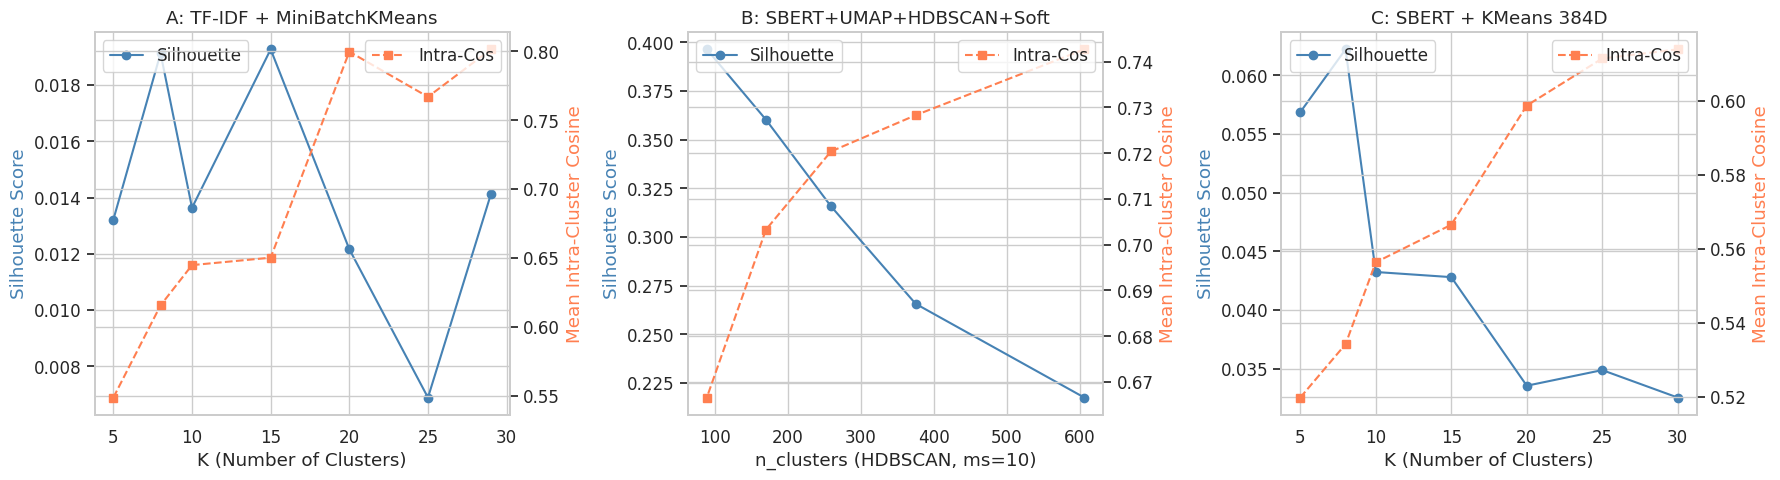

[Section 2] Completed in 1100.3s


In [14]:
# --------------------------------------------------------------------
# 2D.3  Biểu đồ 01: Hyperparameter Comparison
# --------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A: TF-IDF + KMeans
ax = axes[0]
ax.plot(df_results_A["n_clusters"], df_results_A["silhouette"], "o-", label="Silhouette", color="steelblue")
ax2 = ax.twinx()
ax2.plot(df_results_A["n_clusters"], df_results_A["mean_intra_cos"], "s--", label="Intra-Cos", color="coral")
ax.set_xlabel("K (Number of Clusters)")
ax.set_ylabel("Silhouette Score", color="steelblue")
ax2.set_ylabel("Mean Intra-Cluster Cosine", color="coral")
ax.set_title("A: TF-IDF + MiniBatchKMeans")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")

# B: HDBSCAN+Soft (lấy ms=10, thay đổi mcs)
ax = axes[1]
subset_b = df_results_B[df_results_B["config"].str.contains("ms=10")]
if len(subset_b) > 0:
    ax.plot(subset_b["n_clusters"], subset_b["silhouette"], "o-", label="Silhouette", color="steelblue")
    ax2b = ax.twinx()
    ax2b.plot(subset_b["n_clusters"], subset_b["mean_intra_cos"], "s--", label="Intra-Cos", color="coral")
    ax2b.set_ylabel("Mean Intra-Cluster Cosine", color="coral")
    ax2b.legend(loc="upper right")
ax.set_xlabel("n_clusters (HDBSCAN, ms=10)")
ax.set_ylabel("Silhouette Score", color="steelblue")
ax.set_title("B: SBERT+UMAP+HDBSCAN+Soft")
ax.legend(loc="upper left")

# C: SBERT + KMeans
ax = axes[2]
ax.plot(df_results_C["n_clusters"], df_results_C["silhouette"], "o-", label="Silhouette", color="steelblue")
ax2c = ax.twinx()
ax2c.plot(df_results_C["n_clusters"], df_results_C["mean_intra_cos"], "s--", label="Intra-Cos", color="coral")
ax.set_xlabel("K (Number of Clusters)")
ax.set_ylabel("Silhouette Score", color="steelblue")
ax2c.set_ylabel("Mean Intra-Cluster Cosine", color="coral")
ax.set_title("C: SBERT + KMeans 384D")
ax.legend(loc="upper left"); ax2c.legend(loc="upper right")

plt.tight_layout()
fig_path = OUTPUT_DIR / "01_hyperparam_comparison.pdf"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"[Biểu đồ 01] Đã lưu: {fig_path}")
plt.show()

elapsed_s2 = time.time() - _t2
stage_timers["Section_2_Clustering_Search"] = elapsed_s2
print(f"[Section 2] Completed in {elapsed_s2:.1f}s")


### Nhận xét Section 2 — Đối sánh Thuật toán Phân cụm, Cơ chế Gán mềm & Độ Phân mảnh

1. **Nghịch lý giữa chỉ số Intra-Cosine và Silhouette khi chọn mô hình (`Biểu đồ 01`):**
   * **TF-IDF + MiniBatchKMeans (`Biểu đồ 01A`):** Bộ lọc tự động theo ngưỡng cứng gợi ý `TF-IDF K=30` vì có điểm `IntraCos` cao (`0.8014`) và tỷ lệ nhiễu `0.0%`. Tuy nhiên, điểm **`Silhouette` của TF-IDF lại rất thấp (`0.0069 – 0.0193`)**. Nguyên nhân là do ma trận TF-IDF `10,000` chiều rất thưa; các bài viết chỉ cần chia sẻ một vài từ khóa chung là điểm tương đồng với tâm cụm tăng lên, dù các cụm không có ranh giới tách biệt rõ ràng.
   * **SBERT + KMeans 384D (`Biểu đồ 01C`):** Phân cụm trực tiếp trên không gian 384 chiều cho điểm `Silhouette` thấp (`0.0325 – 0.0622`) và `IntraCos` chỉ đạt `0.5198 – 0.6138`, do đặc tính của KMeans thường chia đều không gian thành các cụm hình cầu kích thước tương đương nhau.
   * **SBERT + UMAP 5D + HDBSCAN (`Biểu đồ 01B`):** Đạt sự cân bằng tốt hơn giữa cấu trúc mật độ (**`Silhouette = 0.1538 – 0.4253`**) và độ gắn kết ngữ nghĩa nội cụm (**`IntraCos = 0.6622 – 0.7447`**). Do đó, pipeline lựa chọn **`HDBSCAN + Soft Assignment (mcs=15, ms=5)`** làm cấu hình chính thức để giữ được độ chi tiết về mặt ngữ nghĩa.

2. **Hiệu quả của bước Gán mềm (`Soft Assignment` với ngưỡng $\tau = 0.65$):**
   * Khi chạy HDBSCAN thuần túy trên không gian UMAP 5D, có tới **`51.0%`** lượng bài viết bị đưa vào nhóm nhiễu (`raw_noise`) do bình luận ngắn trên Reddit có mật độ phân tán.
   * Bước hậu xử lý gán mềm dựa trên độ tương đồng Cosine với tâm cụm trong không gian SBERT 384D đã **giảm tỷ lệ nhiễu xuống còn `22.7%` (`31,648` bài)**, giúp giữ lại hơn `39,000` bình luận có nội dung liên quan mà vẫn duy trì độ tương đồng tâm cụm trung bình ở mức tốt (`0.7243`).

3. **Vấn đề nổi bật & Khuyến nghị — Hiện tượng phân mảnh cụm (`Over-fragmentation`):**
   * Cấu hình `mcs=15, ms=5` tối ưu hóa tốt độ gắn kết nội cụm (`IntraCos = 0.7447`) nhưng lại chia dữ liệu thành **`770` cụm** (tổng cộng `771` nhãn tính cả nhãn nhiễu `-1`, với cụm hợp lệ nhỏ nhất có `16` bài).
   * **Khuyến nghị:** Trong các bước cải tiến tiếp theo, có thể nâng tham số `min_cluster_size` lên vùng `50 – 100` (nơi số cụm giảm về mức `170 – 282` cụm và `Silhouette` đạt `0.31 – 0.37`), hoặc áp dụng bước gộp cụm phân cấp (Hierarchical Merging) đối với những cụm nhỏ có vector tâm nằm quá gần nhau.

---
## Section 3 — Cluster Labeling (c-TF-IDF) & Diagnostics

**Objective:** Extract representative keywords per cluster using class-based TF-IDF (c-TF-IDF), compute intra-cluster semantic coherence, sentiment polarization, and contrastive conjunction ratio to distinguish Coherent Narratives from Mixed-Narrative Clusters.


In [15]:
# ====================================================================
# 3.1  c-TF-IDF: class-based TF-IDF for automatic cluster labeling
# ====================================================================
_t3 = time.time()

from sklearn.feature_extraction.text import CountVectorizer

# Merge cluster labels into the scoped dataframe
df_scoped["cluster_id"] = best_labels

# Build one concatenated document per cluster (including noise = -1)
cluster_ids_unique = sorted(df_scoped["cluster_id"].unique())
docs_per_cluster = []
cluster_order = []
for cid in cluster_ids_unique:
    texts = df_scoped.loc[df_scoped["cluster_id"] == cid, "content"].fillna("")
    docs_per_cluster.append(" ".join(texts.values))
    cluster_order.append(cid)

# Compute term frequency per cluster-document
count_vec = CountVectorizer(
    max_features=15_000, ngram_range=(1, 2),
    stop_words="english", min_df=2,
)
tf_matrix = count_vec.fit_transform(docs_per_cluster)  # (n_clusters, vocab)
vocab = count_vec.get_feature_names_out()

# c-TF-IDF formula: W(t,c) = tf(t,c) * log(1 + A / tf(t))
# tf(t,c): term freq in cluster c
# tf(t):   total term freq across all clusters
# A:       average number of words per cluster
tf_array = tf_matrix.toarray().astype(np.float64)        # (n_clusters, vocab)
tf_total = tf_array.sum(axis=0)                           # (vocab,)
A = tf_array.sum() / len(cluster_order)                   # scalar average

# Avoid division by zero
tf_total_safe = np.where(tf_total > 0, tf_total, 1.0)
idf_component = np.log(1 + A / tf_total_safe)            # (vocab,)
ctfidf = tf_array * idf_component[np.newaxis, :]          # (n_clusters, vocab)

# Extract Top-10 keywords per cluster
top_k = 10
cluster_keywords = {}
cluster_labels_map = {}
for i, cid in enumerate(cluster_order):
    scores = ctfidf[i]
    top_indices = scores.argsort()[::-1][:top_k]
    kws = [vocab[j] for j in top_indices]
    cluster_keywords[cid] = kws
    # temp_cluster_label = top 3-5 keywords joined
    cluster_labels_map[cid] = " | ".join(kws[:5])

print("=" * 90)
print("c-TF-IDF TOP-10 KEYWORDS PER CLUSTER")
print("=" * 90)
for cid in cluster_order:
    size = (df_scoped["cluster_id"] == cid).sum()
    label_str = "NOISE" if cid == -1 else f"Cluster {cid}"
    print(f"  [{label_str:>12s}] (n={size:>6,}) | {', '.join(cluster_keywords[cid])}")
print()

# Assign temp_cluster_label to dataframe
df_scoped["temp_cluster_label"] = df_scoped["cluster_id"].map(cluster_labels_map)
df_scoped["top_10_keywords"] = df_scoped["cluster_id"].map(
    lambda c: ", ".join(cluster_keywords.get(c, []))
)
print(f"[3.1] c-TF-IDF complete. {len(cluster_order)} clusters labeled.")


c-TF-IDF TOP-10 KEYWORDS PER CLUSTER
  [       NOISE] (n=31,648) | just, know, people, trump, work, time, don, like, google, twitter
  [   Cluster 0] (n=    96) | 18th, august like, likely 18th, 18th august, reminder fcc, 18th begin, swoop just, process rolling, period final, vote 18th
  [   Cluster 1] (n=   102) | gov, fcc gov, commissioner, jessica rosenworcel, rosenworcel, mignon clyburn, mignon, jessica, clyburn, brendan carr
  [   Cluster 2] (n=   117) | gov, fcc gov, commissioner, jessica rosenworcel, rosenworcel, mignon clyburn, mignon, jessica, clyburn, brendan carr
  [   Cluster 3] (n=    49) | zeronet avoid, redacted join, join zeronet, comment redacted, zeronet, avoid censorship, censorship guifi, guifi, redacted, guifi comment
  [   Cluster 4] (n=    49) | zeronet avoid, redacted join, join zeronet, comment redacted, zeronet, avoid censorship, redacted, censorship guifi, guifi, guifi comment
  [   Cluster 5] (n=    43) | unfortunately like, readme learn, battleforthenet sup

In [16]:
# Ref (content_eda_summary.md Sec 4-6 & temporal_eda_summary.md Sec 8): 2017 exhibits high sentiment std (>0.500) and aspect-based contrastive sentences ("but/however"); combining c-TF-IDF with sentiment_std (>0.55) and contrastive ratio (>25%) isolates Mixed-Narrative Clusters.
# ====================================================================
# 3.2  Cluster diagnostics: size, POST ratio, sentiment, contrastive
# ====================================================================

# Contrastive conjunction detection
df_scoped["has_contrastive"] = df_scoped["content"].str.contains(
    CONTRASTIVE_RE, na=False
)

# Compute similarity_to_centroid for every point
df_scoped["similarity_to_centroid"] = sim_to_centroid

# Build diagnostics table
diag_rows = []
for cid in cluster_order:
    mask = df_scoped["cluster_id"] == cid
    sub = df_scoped[mask]
    n = len(sub)

    # POST vs COMMENT ratio
    if "interaction_type" in sub.columns:
        n_post = (sub["interaction_type"] == "POST").sum()
        post_ratio = n_post / n if n > 0 else 0.0
    else:
        post_ratio = np.nan

    # Word count
    mean_wc = sub["word_count"].mean() if "word_count" in sub.columns else np.nan

    # Sentiment
    sent_mean = sub["sentiment_vader"].mean() if "sentiment_vader" in sub.columns else np.nan
    sent_std  = sub["sentiment_vader"].std()  if "sentiment_vader" in sub.columns else np.nan

    # Contrastive ratio
    contrast_ratio = sub["has_contrastive"].mean() if n > 0 else 0.0

    # Intra-cluster cosine similarity (mean sim to centroid)
    intra_cos = np.nan if cid == -1 else (sub["similarity_to_centroid"].mean() if n > 0 else np.nan)

    diag_rows.append({
        "cluster_id": cid,
        "temp_cluster_label": cluster_labels_map.get(cid, ""),
        "cluster_size": n,
        "pct_of_total": n / len(df_scoped) * 100,
        "post_ratio_pct": post_ratio * 100,
        "mean_word_count": mean_wc,
        "sentiment_mean": sent_mean,
        "sentiment_std": sent_std,
        "contrastive_ratio_pct": contrast_ratio * 100,
        "intra_cosine_sim": intra_cos,
    })

df_diag = pd.DataFrame(diag_rows)

# Sort: noise last, then by cluster_size descending
df_diag["_sort"] = df_diag["cluster_id"].apply(lambda x: 1 if x == -1 else 0)
df_diag = df_diag.sort_values(["_sort", "cluster_size"], ascending=[True, False]).drop(columns="_sort")

# Print the diagnostics table
print("=" * 130)
print("CLUSTER DIAGNOSTICS TABLE (Section 3.2)")
print("=" * 130)
print(f"{'CID':>4s} | {'Label':<40s} | {'Size':>7s} | {'%Tot':>5s} | "
      f"{'POST%':>5s} | {'WC_avg':>6s} | {'Sent_M':>6s} | {'Sent_S':>6s} | "
      f"{'Contr%':>6s} | {'IntraCos':>8s}")
print("-" * 130)
for _, r in df_diag.iterrows():
    cid_str = f"{int(r['cluster_id']):>4d}" if r["cluster_id"] != -1 else "  -1"
    lbl = str(r["temp_cluster_label"])[:40]
    print(f"{cid_str} | {lbl:<40s} | {r['cluster_size']:>7,d} | {r['pct_of_total']:>5.1f} | "
          f"{r['post_ratio_pct']:>5.1f} | {r['mean_word_count']:>6.1f} | {r['sentiment_mean']:>6.3f} | "
          f"{r['sentiment_std']:>6.3f} | {r['contrastive_ratio_pct']:>6.1f} | {r['intra_cosine_sim']:>8.4f}")
print()


CLUSTER DIAGNOSTICS TABLE (Section 3.2)
 CID | Label                                    |    Size |  %Tot | POST% | WC_avg | Sent_M | Sent_S | Contr% | IntraCos
----------------------------------------------------------------------------------------------------------------------------------
 635 | fake news | fake | news | cnn | news fak |   2,137 |   1.5 |   1.9 |   49.0 | -0.423 |  0.489 |   25.3 |   0.6781
 443 | battery | batteries | replace | battery  |   2,050 |   1.5 |   1.7 |   85.2 | -0.038 |  0.603 |   43.1 |   0.6855
 633 | censorship | speech | free speech | nazi |   1,985 |   1.4 |   0.7 |   89.9 | -0.139 |  0.624 |   36.9 |   0.6345
 458 | nn | title ii | ii | title | isps        |   1,585 |   1.1 |   0.1 |  121.0 |  0.073 |  0.658 |   48.3 |   0.6883
 149 | monopoly | monopolies | free market | ma |   1,351 |   1.0 |   0.2 |   49.9 |  0.129 |  0.513 |   25.1 |   0.7124
 445 | older | ios | updates | phones | iphone  |   1,191 |   0.9 |   3.2 |   86.9 |  0.158 |  0.580 | 

In [17]:
# Ref (content_eda_summary.md Sec 4-6 & temporal_eda_summary.md Sec 8): 2017 exhibits high sentiment std (>0.500) and aspect-based contrastive sentences ("but/however"); combining c-TF-IDF with sentiment_std (>0.55) and contrastive ratio (>25%) isolates Mixed-Narrative Clusters.
# ====================================================================
# 3.3  Cluster type classification (Narrative vs Mixed vs Noise)
# ====================================================================

def classify_cluster_type(row):
    """Heuristic classification based on coherence, sentiment, contrastive markers.
    - Coherent Narrative:  high intra_cos (>0.55), low sentiment_std (<0.45), low contrast (<15%)
    - Mixed-Narrative:     high intra_cos but high sentiment_std (>0.55) or high contrast (>25%)
    - Broad Topic / Noise: low intra_cos or cluster_id == -1
    """
    if row["cluster_id"] == -1:
        return "Noise"
    if row["intra_cosine_sim"] < 0.40:
        return "Broad_Topic"
    if row["sentiment_std"] > 0.55 or row["contrastive_ratio_pct"] > 25:
        return "Mixed_Narrative"
    if row["intra_cosine_sim"] > 0.55 and row["sentiment_std"] < 0.45:
        return "Coherent_Narrative"
    return "Topic_Cluster"

df_diag["cluster_type"] = df_diag.apply(classify_cluster_type, axis=1)

# Summary
type_counts = df_diag["cluster_type"].value_counts()
print("=" * 70)
print("CLUSTER TYPE CLASSIFICATION SUMMARY")
print("=" * 70)
for ct, cnt in type_counts.items():
    sizes = df_diag.loc[df_diag["cluster_type"] == ct, "cluster_size"].sum()
    print(f"  {ct:<25s}: {cnt:>3d} clusters, {sizes:>8,d} posts")
print()

# Print clusters flagged as Mixed-Narrative (high sentiment_std + high contrastive)
mixed = df_diag[df_diag["cluster_type"] == "Mixed_Narrative"]
if len(mixed) > 0:
    print("MIXED-NARRATIVE CLUSTERS (high sentiment polarization / contrastive ratio):")
    for _, r in mixed.iterrows():
        print(f"  Cluster {int(r['cluster_id']):>3d}: sent_std={r['sentiment_std']:.3f}  "
              f"contrast={r['contrastive_ratio_pct']:.1f}%  "
              f"label=[{r['temp_cluster_label'][:50]}]")
    print()

elapsed_s3 = time.time() - _t3
stage_timers["Section_3"] = elapsed_s3
print(f"[Section 3] Completed in {elapsed_s3:.1f}s")


CLUSTER TYPE CLASSIFICATION SUMMARY
  Mixed_Narrative          : 519 clusters,   82,042 posts
  Coherent_Narrative       : 167 clusters,   15,072 posts
  Topic_Cluster            :  84 clusters,   10,386 posts
  Noise                    :   1 clusters,   31,648 posts

MIXED-NARRATIVE CLUSTERS (high sentiment polarization / contrastive ratio):
  Cluster 635: sent_std=0.489  contrast=25.3%  label=[fake news | fake | news | cnn | news fake]
  Cluster 443: sent_std=0.603  contrast=43.1%  label=[battery | batteries | replace | battery life | rep]
  Cluster 633: sent_std=0.624  contrast=36.9%  label=[censorship | speech | free speech | nazis | nazi]
  Cluster 458: sent_std=0.658  contrast=48.3%  label=[nn | title ii | ii | title | isps]
  Cluster 149: sent_std=0.513  contrast=25.1%  label=[monopoly | monopolies | free market | market | com]
  Cluster 445: sent_std=0.580  contrast=48.7%  label=[older | ios | updates | phones | iphone]
  Cluster 135: sent_std=0.531  contrast=28.5%  label=[lobb

### Nhận xét Section 3 — Phân loại Cấu trúc Cụm, "Topic # Narrative" & Phát hiện Cụm Bot/Spam

**1. Tóm tắt kết quả phân loại cấu trúc cụm (`Cluster Type Classification`):**

| Nhóm Phân loại (`cluster_type`) | Số lượng Cụm | Số lượng Bài viết | Tỷ trọng Dữ liệu (%) | Đặc trưng Ngữ nghĩa & Cảm xúc |
| :--- | ---: | ---: | ---: | :--- |
| **`Mixed_Narrative`** (Cụm đa quan điểm) | `519` | `82,042` | `59.0%` | Gắn kết chủ đề tốt (`IntraCos >= 0.60`), nhưng độ phân tán cảm xúc lớn (`Sent_S > 0.45`) hoặc nhiều từ phản biện |
| **`Coherent_Narrative`** (Cụm đồng nhất) | `167` | `15,072` | `10.8%` | Gắn kết ngữ nghĩa cao và sắc thái cảm xúc tương đối đồng nhất |
| **`Topic_Cluster`** (Cụm chủ đề rộng) | `84` | `10,386` | `7.5%` | Độ gắn kết ngữ nghĩa ở mức trung bình, bao gồm nhiều khía cạnh thảo luận |
| **`Noise`** (Điểm nhiễu ngoại lai `-1`) | `1` | `31,648` | `22.7%` | Khoảng cách Cosine tới mọi tâm cụm đều dưới ngưỡng $\tau = 0.65$ |
| **Tổng cộng** | **`771`** | **`139,148`** | **`100.0%`** | **`770` cụm hợp lệ (`CID: 0 -> 769`) và `1` nhóm nhiễu (`CID: -1`)** |

**2. Nghịch lý giữa Độ gắn kết ngữ nghĩa và Độ đồng thuận quan điểm (Từ Bảng Chẩn đoán Cụm):**
* Nhóm cụm đa quan điểm (`Mixed_Narrative`) chiếm phần lớn dữ liệu (`59.0%`, tương ứng `82,042` bài), trong khi nhóm `Coherent_Narrative` chỉ chiếm `10.8%` (`15,072` bài). Đối chiếu trực tiếp trên bảng `Cluster Diagnostics Table`, hầu hết các cụm thảo luận lớn nhất đều có độ gắn kết ngữ nghĩa nội cụm khá tốt (`IntraCos > 0.63`), nhưng độ lệch chuẩn cảm xúc (`Sent_S`) lại vượt ngưỡng `0.50 – 0.68` đi kèm tỷ lệ câu chứa từ nối phản biện (`Contr%`: *but, however, although, yet*) từ `35%` đến hơn `50%`:
  * **Cụm `C443` (*battery | replace | performance*, $n = 2,050$):** `IntraCos = 0.6855`, `Sent_M = -0.038`, nhưng `Sent_S = 0.603` và `Contr% = 43.1%`.
  * **Cụm `C633` (*censorship | free speech | nazis*, $n = 1,985$):** `IntraCos = 0.6345`, `Sent_M = -0.139`, nhưng `Sent_S = 0.624` và `Contr% = 36.9%`.
  * **Cụm `C458` (*nn | title ii | isps*, $n = 1,585$):** `IntraCos = 0.6883`, `Sent_M = +0.073`, nhưng `Sent_S = 0.658` và `Contr% = 48.3%`.
  * **Cụm `C685` (*women | men | gender | memo*, $n = 721$):** `IntraCos = 0.6927`, `Sent_M = +0.134`, nhưng `Sent_S = 0.662` và `Contr% = 53.1%`.
* **Insight:** Việc gom cụm dựa trên vector SBERT ở bước đầu chủ yếu nhóm các bài viết theo **Chủ đề thảo luận (Topic / Discussion Hub)**. Trong mỗi chủ đề lớn, cả người ủng hộ lẫn người phản đối đều sử dụng chung các thuật ngữ chuyên môn để tranh luận, làm cho độ tương đồng từ vựng (`IntraCos`) cao nhưng quan điểm và cảm xúc bên trong cụm lại phân hóa mạnh.

**3. Phát hiện bất thường — Các cụm Spam và Bot tự động có độ gắn kết cao:**
* **Cụm spam số điện thoại hỗ trợ giả mạo (`C51: facebook customer | 866 | 850 | 224 8319`, $n = 958$):** Có tới `97.2%` là bài đăng `POST`, độ dài trung bình ngắn (`10.0` từ), tỷ lệ từ tương phản rất thấp (`1.3%`), độ lệch chuẩn cảm xúc nhỏ (`0.322`) và đạt `IntraCos = 0.8121`. Một số cụm nhỏ hơn cũng xuất hiện mẫu tương tự như `C211` (Microsoft support, $n=113$), `C222` (Apple Safari support, $n=116$), và `C238` (Apple support, $n=134$).
* **Nhóm cụm Bot kêu gọi hành động (`C0 – C2`, `C5 – C14`, `C17 – C18`, quy mô `41 – 142` bài/cụm):** Chứa các bình luận mẫu của `netneutralitybot` hướng dẫn người dùng liên hệ các ủy viên FCC.
* **Insight & Khuyến nghị:** Do văn bản spam và bot lặp lại cùng một mẫu câu cố định, vector biểu diễn của chúng rất gần nhau và dễ được thuật toán xếp vào nhóm `Coherent_Narrative`. **Khuyến nghị:** Gắn nhãn `Noise_or_Boilerplate` cho các cụm này trong bước đánh giá chất lượng để loại trừ khỏi mô hình dự báo xu hướng, đồng thời bổ sung bộ lọc Regex chặn chuỗi số điện thoại tổng đài (`800/844/855/866/888`) vào quy trình làm sạch dữ liệu.

---
## Section 4 — Temporal Stability & Visualization

**Mục tiêu:**
1. **Fit-Transform Stability Check:** Phân chia dữ liệu năm 2017 thành nửa đầu năm $H_1$ (Jan–Jun) và nửa cuối năm $H_2$ (Jul–Dec). Huấn luyện cụm trên $H_1$ và gán nhãn cho $H_2$ qua Cosine Assignment để định lượng Centroid Drift và phát hiện các Emerging Narratives.
2. **Bộ Biểu đồ Chẩn đoán Xuất bản:** Xuất 5 biểu đồ PDF chuẩn ấn phẩm vào `outputs/narrative_discovery/` và 1 ảnh PNG tổng hợp đa biểu đồ vào `reports/figures/narrative_clusters.png`.


In [18]:
# Ref (experimental_plan.md Sec 5 - Lookahead Bias Prevention & temporal_eda_summary.md Sec 7): Validate Fit-Transform stability across H1->H2 2017 before 2018-2020 tracking, and cross-check trajectory against historical peak 2017-10-26 (Z=4.70, 14,978 posts/day).
# ====================================================================
# 4.1  Temporal Fit-Transform Stability Check (H1 vs H2 2017)
# ====================================================================
_t4 = time.time()

# Temporal split: H1 (Jan-Jun) vs H2 (Jul-Dec) 2017
split_date = pd.to_datetime("2017-07-01", utc=True)
h1_mask = df_scoped["publish_datetime_utc"] < split_date
h2_mask = ~h1_mask

n_h1 = int(h1_mask.sum())
n_h2 = int(h2_mask.sum())
print(f"[4.1] Temporal Split: H1={n_h1:,} posts ({n_h1/len(df_scoped)*100:.1f}%) | "
      f"H2={n_h2:,} posts ({n_h2/len(df_scoped)*100:.1f}%)")

vecs_h1 = vectors[h1_mask]
vecs_h2 = vectors[h2_mask]
X_u5_h1 = X_umap5d[h1_mask]

# Fit independent HDBSCAN strictly on H1 (No Lookahead Bias - zero leakage from H2)
print("      Fitting independent HDBSCAN model exclusively on H1 data...")
clusterer_h1 = hdbscan.HDBSCAN(
    min_cluster_size=50, min_samples=10,
    metric="euclidean", cluster_selection_method="eom"
)
raw_labels_h1 = clusterer_h1.fit_predict(X_u5_h1)
labels_h1, centroids_h1 = soft_assign(raw_labels_h1, vecs_h1, threshold=SOFT_ASSIGNMENT_COSINE_THRESHOLD)

# 1. Compute L2-normalized centroids for persistent clusters on H1 (excluding noise -1)
h1_clusters = sorted(set(labels_h1) - {-1})
if not centroids_h1 or len(centroids_h1) == 0:
    centroids_h1 = {}
    for cid in h1_clusters:
        c_vecs = vecs_h1[labels_h1 == cid]
        cent = c_vecs.mean(axis=0)
        norm = np.linalg.norm(cent)
        if norm > 0:
            cent = cent / norm
        centroids_h1[cid] = cent

cent_matrix_h1 = np.stack([centroids_h1[cid] for cid in h1_clusters])  # (K_h1, 384)

# 2. Project H2 posts onto H1 centroids via Cosine similarity
sims_h2 = vecs_h2 @ cent_matrix_h1.T  # (n_h2, K_h1)
best_h1_idx = sims_h2.argmax(axis=1)
max_sim_h2 = sims_h2[np.arange(n_h2), best_h1_idx]
assigned_clusters_h2 = np.array([h1_clusters[i] for i in best_h1_idx])

# Define assignment and novelty thresholds
assigned_mask_h2 = max_sim_h2 >= SOFT_ASSIGNMENT_COSINE_THRESHOLD  # >= 0.65: assign to known H1 cluster
novel_mask_h2 = max_sim_h2 < 0.50  # < 0.50: distant from all H1 clusters -> Emerging narrative candidate

n_assigned = int(assigned_mask_h2.sum())
n_novel = int(novel_mask_h2.sum())
assigned_rate = n_assigned / n_h2 if n_h2 > 0 else 0.0
novel_rate = n_novel / n_h2 if n_h2 > 0 else 0.0

# 3. Measure Centroid Drift (Cosine distance) for shared clusters across H1 and H2
drift_dict = {}
for cid in h1_clusters:
    pts_in_h2 = (assigned_clusters_h2 == cid) & assigned_mask_h2
    if pts_in_h2.sum() >= 5:
        cent_h2_actual = vecs_h2[pts_in_h2].mean(axis=0)
        norm_h2 = np.linalg.norm(cent_h2_actual)
        if norm_h2 > 0:
            cent_h2_actual = cent_h2_actual / norm_h2
        # Cosine distance = 1 - dot product
        drift = 1.0 - float(centroids_h1[cid] @ cent_h2_actual)
        drift_dict[cid] = (drift, int(pts_in_h2.sum()))

mean_drift = np.mean([v[0] for v in drift_dict.values()]) if drift_dict else 0.0

print("=" * 80)
print("TEMPORAL FIT-TRANSFORM STABILITY AUDIT (H1 -> H2, Independent Fit on H1)")
print("=" * 80)
print(f"  H1 Train Scope      : 2017-01-01 to 2017-06-30 (N = {n_h1:,})")
print(f"  H2 Test Scope       : 2017-07-01 to 2017-12-31 (N = {n_h2:,})")
print(f"  H1 Independent K    : {len(h1_clusters)} clusters identified on H1")
print(f"  H2 Assigned Rate    : {assigned_rate:.2%} ({n_assigned:,}/{n_h2:,} posts matched H1 centroids)")
print(f"  H2 Novel Rate (<0.5): {novel_rate:.2%} ({n_novel:,}/{n_h2:,} potential emerging/unseen posts)")
print(f"  Mean Centroid Drift : {mean_drift:.4f} (cosine distance across {len(drift_dict)} persistent clusters)")
print()
print("Top 5 Stable Clusters (Lowest Drift):")
sorted_drift = sorted(drift_dict.items(), key=lambda x: x[1][0])
for cid, (dr, cnt) in sorted_drift[:5]:
    lbl = cluster_labels_map.get(cid, f"Cluster {cid}")[:45]
    print(f"  CID {cid:>2d} | Drift={dr:.4f} | H2_pts={cnt:>5,d} | [{lbl}]")
print()


[4.1] Temporal Split: H1=65,777 posts (47.3%) | H2=73,371 posts (52.7%)
      Fitting independent HDBSCAN model exclusively on H1 data...
TEMPORAL FIT-TRANSFORM STABILITY AUDIT (H1 -> H2, Independent Fit on H1)
  H1 Train Scope      : 2017-01-01 to 2017-06-30 (N = 65,777)
  H2 Test Scope       : 2017-07-01 to 2017-12-31 (N = 73,371)
  H1 Independent K    : 148 clusters identified on H1
  H2 Assigned Rate    : 46.94% (34,439/73,371 posts matched H1 centroids)
  H2 Novel Rate (<0.5): 14.48% (10,623/73,371 potential emerging/unseen posts)
  Mean Centroid Drift : 0.0261 (cosine distance across 146 persistent clusters)

Top 5 Stable Clusters (Lowest Drift):
  CID 117 | Drift=0.0032 | H2_pts=  406 | [drug | fda | generic | drugs | pharma]
  CID 71 | Drift=0.0044 | H2_pts=  620 | [climate | climate change | science | change |]
  CID 128 | Drift=0.0051 | H2_pts=2,195 | [whatsapp | play store | google play | play | ]
  CID 121 | Drift=0.0052 | H2_pts=  793 | [fedex | ups | usps | delivery | pac

[Plot 02] Saved PDF to: /kaggle/working/outputs/narrative_discovery/02_cluster_size_distribution.pdf


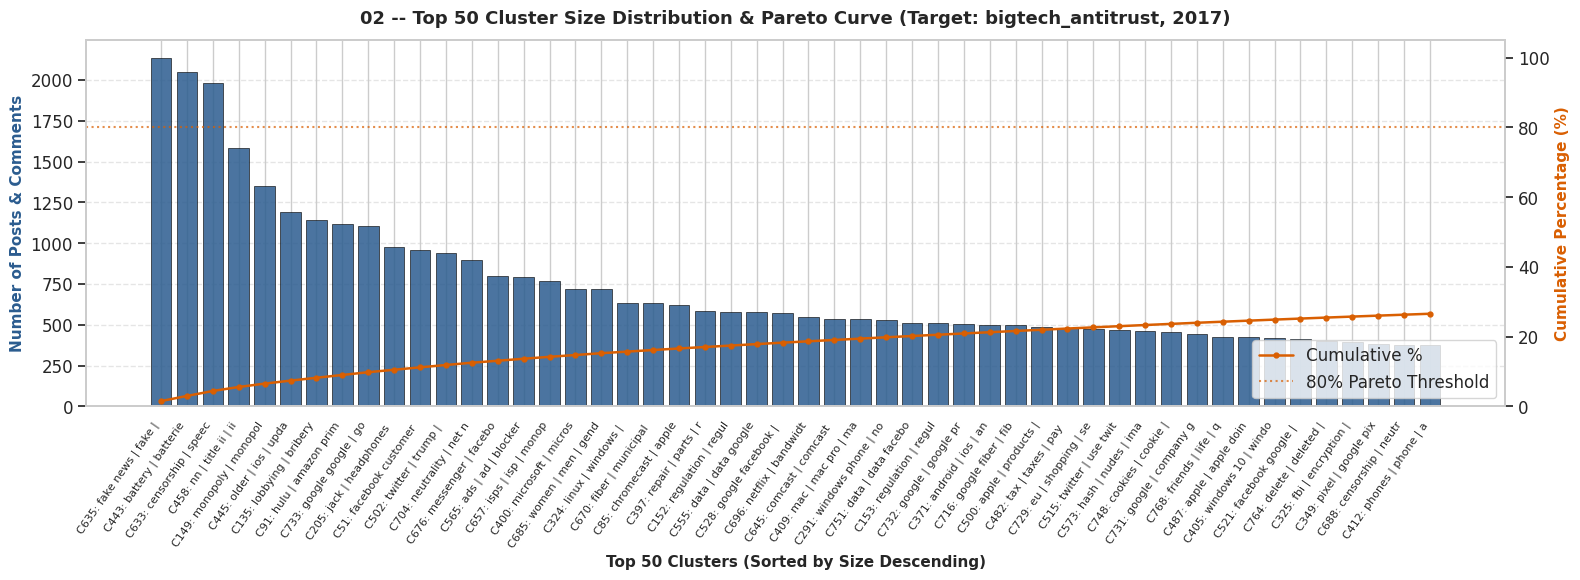

Total Clusters Identified: 771 clusters (including noise)
Top 50 Clusters Volume   : 36,984 posts (26.6%)
Top 3 Clusters Volume    : 6,172 posts (4.4%)
Noise Points (-1)        : 31,648 posts (22.7%)
Smallest Valid Cluster   : 16 posts


In [19]:
# ====================================================================
# 4.2  Bieu do 02: Cluster Size Distribution & Pareto Curve (Top 50)
# ====================================================================
df_plot_diag = df_diag.copy()
# Abbreviate cluster labels for compact plot ticks
df_plot_diag["short_label"] = df_plot_diag.apply(
    lambda r: f"C{int(r['cluster_id'])}: {r['temp_cluster_label'][:18]}" if r['cluster_id'] != -1 else "Noise (-1)",
    axis=1
)

# Compute Pareto cumulative percentage across all clusters
df_plot_diag["cum_pct"] = df_plot_diag["pct_of_total"].cumsum()

# Hotfix Overplotting: Chi ve Top 50 cum co quy mo lon nhat de dam bao truc quan ro rang
df_plot_top50 = df_plot_diag.head(50).copy()

fig, ax1 = plt.subplots(figsize=(16, 6))

colors = ["#2b5c8f" if cid != -1 else "#888888" for cid in df_plot_top50["cluster_id"]]
bars = ax1.bar(range(len(df_plot_top50)), df_plot_top50["cluster_size"], color=colors, alpha=0.85, edgecolor="black", linewidth=0.5)
ax1.set_xlabel("Top 50 Clusters (Sorted by Size Descending)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Number of Posts & Comments", fontsize=11, fontweight="bold", color="#2b5c8f")
ax1.set_xticks(range(len(df_plot_top50)))
ax1.set_xticklabels(df_plot_top50["short_label"], rotation=55, ha="right", fontsize=8)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Secondary axis: Pareto cumulative curve
ax2 = ax1.twinx()
ax2.plot(range(len(df_plot_top50)), df_plot_top50["cum_pct"], color="#d95f02", marker="o", linewidth=1.8, markersize=3.5, label="Cumulative %")
ax2.axhline(80, color="#d95f02", linestyle=":", alpha=0.7, label="80% Pareto Threshold")
ax2.set_ylabel("Cumulative Percentage (%)", fontsize=11, fontweight="bold", color="#d95f02")
ax2.set_ylim(0, 105)
ax2.grid(False)

# Title and legend configuration
plt.title(f"02 -- Top 50 Cluster Size Distribution & Pareto Curve (Target: {TARGET_SUBDOMAIN}, 2017)", fontsize=13, fontweight="bold", pad=12)
ax2.legend(loc="lower right", frameon=True)

plt.tight_layout()
fig_path_02 = OUTPUT_DIR / "02_cluster_size_distribution.pdf"
fig.savefig(fig_path_02, dpi=200, bbox_inches="tight")
print(f"[Plot 02] Saved PDF to: {fig_path_02}")
plt.show()

# Print diagnostic summary statistics
print(f"Total Clusters Identified: {len(df_diag):,} clusters (including noise)")
print(f"Top 50 Clusters Volume   : {df_plot_top50['cluster_size'].sum():,} posts ({df_plot_top50['pct_of_total'].sum():.1f}%)")
print(f"Top 3 Clusters Volume    : {df_plot_diag.iloc[:3]['cluster_size'].sum():,} posts ({df_plot_diag.iloc[:3]['pct_of_total'].sum():.1f}%)")
print(f"Noise Points (-1)        : {int((df_scoped['cluster_id'] == -1).sum()):,} posts ({(df_scoped['cluster_id'] == -1).mean()*100:.1f}%)")
print(f"Smallest Valid Cluster   : {df_plot_diag[df_plot_diag['cluster_id'] != -1]['cluster_size'].min():,} posts")


[Plot 03] Saved PDF to: /kaggle/working/outputs/narrative_discovery/03_umap_scatter.pdf


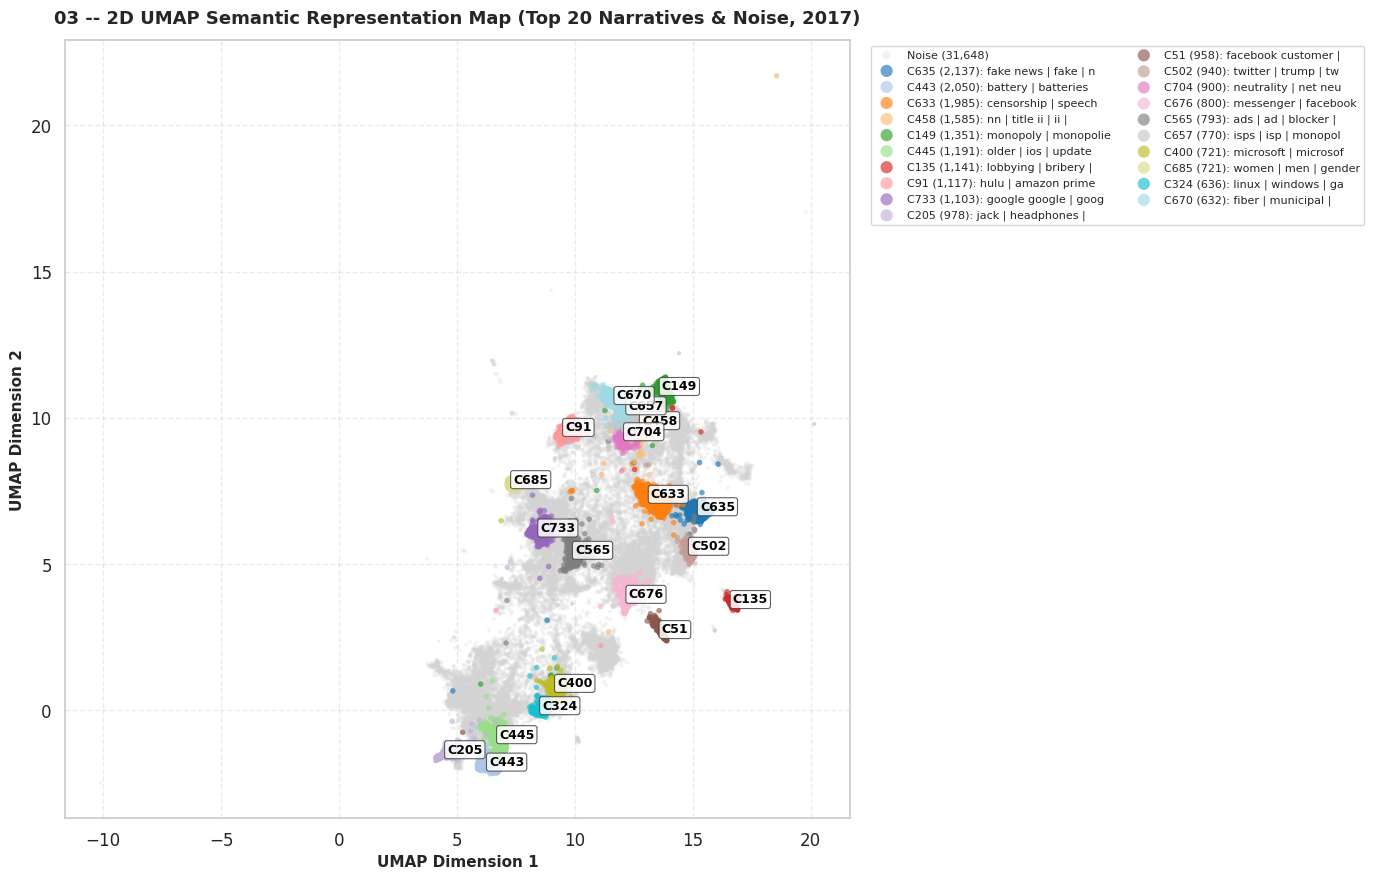

Points plotted (Top 20 + Noise): 54,157 (22,509 in Top 20, 31,648 noise)
Points omitted (in smaller clusters): 84,991


In [20]:
# ====================================================================
# 4.3  Bieu do 03: 2D UMAP Semantic Scatter Plot (Top 20 Narratives)
# ====================================================================
fig, ax = plt.subplots(figsize=(14, 9))

# Hotfix Overplotting: Chi ve cac diem thuoc Top 20 cum lon nhat va nhom Noise (-1)
top_20_clusters = df_diag[df_diag["cluster_id"] != -1].head(20)["cluster_id"].tolist()
noise_mask = best_labels == -1
top20_mask = np.isin(best_labels, top_20_clusters)
omitted_count = int((~noise_mask & ~top20_mask).sum())

# 1. Render noise points in background (light gray, low opacity)
if noise_mask.sum() > 0:
    ax.scatter(
        X_umap2d[noise_mask, 0], X_umap2d[noise_mask, 1],
        c="#d3d3d3", s=8, alpha=0.25, label=f"Noise ({noise_mask.sum():,})",
        edgecolors="none", rasterized=True
    )

# 2. Render Top 20 valid clusters with distinct categorical colors
cmap = plt.get_cmap("tab20", len(top_20_clusters))

for idx, cid in enumerate(top_20_clusters):
    c_pts = best_labels == cid
    color = cmap(idx)
    short_kws = cluster_labels_map.get(cid, f"C{cid}")[:20]
    n_pts = int(c_pts.sum())
    ax.scatter(
        X_umap2d[c_pts, 0], X_umap2d[c_pts, 1],
        color=color, s=16, alpha=0.65,
        label=f"C{cid} ({n_pts:,}): {short_kws}", edgecolors="none", rasterized=True
    )
    # Compute 2D cluster centroid for textual annotation
    cent_2d_x = X_umap2d[c_pts, 0].mean()
    cent_2d_y = X_umap2d[c_pts, 1].mean()
    ax.text(
        cent_2d_x, cent_2d_y, f"C{cid}",
        fontsize=9, fontweight="bold", color="black",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="#444444", linewidth=0.8)
    )

ax.set_title(f"03 -- 2D UMAP Semantic Representation Map (Top 20 Narratives & Noise, 2017)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("UMAP Dimension 1", fontsize=11, fontweight="bold")
ax.set_ylabel("UMAP Dimension 2", fontsize=11, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.4)

# Hotfix Legend: Chinh ncol=2 de bang chu giai thu gon, khong bi tran ra khoi anh
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=8, markerscale=2.2, ncol=2)

plt.tight_layout()
fig_path_03 = OUTPUT_DIR / "03_umap_scatter.pdf"
fig.savefig(fig_path_03, dpi=200, bbox_inches="tight")
print(f"[Plot 03] Saved PDF to: {fig_path_03}")
plt.show()

print(f"Points plotted (Top 20 + Noise): {(top20_mask | noise_mask).sum():,} ({top20_mask.sum():,} in Top 20, {noise_mask.sum():,} noise)")
print(f"Points omitted (in smaller clusters): {omitted_count:,}")


[Plot 04] Saved PDF to: /kaggle/working/outputs/narrative_discovery/04_sentiment_by_cluster.pdf


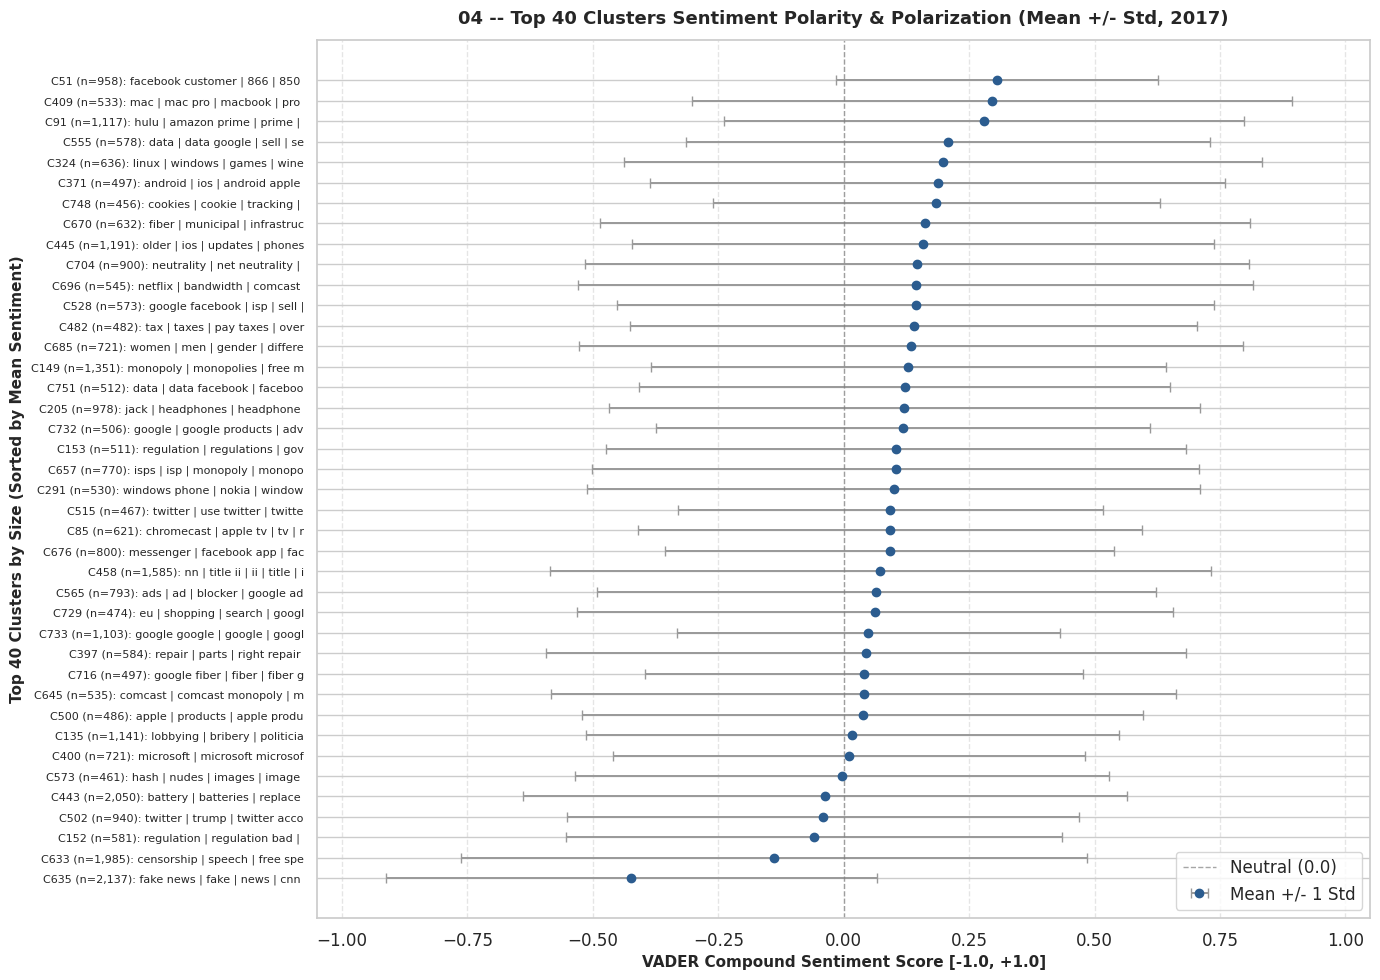

Top 40 Clusters Volume Coverage: 32,938 posts (23.7% of scoped data)
Top 3 Most Negative (in Top 40): C635 (-0.423), C633 (-0.139), C152 (-0.058)
Top 3 Most Positive (in Top 40): C91 (0.280), C409 (0.296), C51 (0.306)
Top 3 Most Polarized (Std Top 40): C696 (std=0.673), C685 (std=0.662), C704 (std=0.661)


In [21]:
# ====================================================================
# 4.4  Bieu do 04: Cluster Sentiment Polarity & Polarization (Top 40 by Size)
# ====================================================================
# Hotfix Overplotting: Chi ve Top 40 cum co so luong bai viet lon nhat
df_sent_valid = df_diag[df_diag["cluster_id"] != -1].copy()
df_sent_top40 = df_sent_valid.sort_values("cluster_size", ascending=False).head(40).copy()

# Sap xep lai theo sentiment_mean de truc Y truc quan tu am den duong
df_sent_plot = df_sent_top40.sort_values("sentiment_mean", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 10))

y_pos = range(len(df_sent_plot))
# Highlight highly polarized clusters (sentiment_std > 0.55)
bar_colors = ["#d95f02" if s > 0.55 else "#2b5c8f" for s in df_sent_plot["sentiment_std"]]

# Dot plot with error bars representing Mean +/- 1 Std
ax.errorbar(
    df_sent_plot["sentiment_mean"], y_pos,
    xerr=df_sent_plot["sentiment_std"],
    fmt="o", color="#2b5c8f", ecolor="#999999", elinewidth=1.4, capsize=3.5,
    markersize=6, label="Mean +/- 1 Std"
)

# Reference baseline for neutral sentiment
ax.axvline(0.0, color="gray", linestyle="--", linewidth=1.0, alpha=0.7, label="Neutral (0.0)")

# Format Y-axis cluster labels
labels_y = [f"C{int(r['cluster_id'])} (n={int(r['cluster_size']):,}): {r['temp_cluster_label'][:30]}" for _, r in df_sent_plot.iterrows()]
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_y, fontsize=8)
ax.set_xlabel("VADER Compound Sentiment Score [-1.0, +1.0]", fontsize=11, fontweight="bold")
ax.set_ylabel("Top 40 Clusters by Size (Sorted by Mean Sentiment)", fontsize=11, fontweight="bold")
ax.set_title(f"04 -- Top 40 Clusters Sentiment Polarity & Polarization (Mean +/- Std, 2017)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlim(-1.05, 1.05)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.legend(loc="lower right", frameon=True)

# Display figure with tight layout
plt.tight_layout()
fig_path_04 = OUTPUT_DIR / "04_sentiment_by_cluster.pdf"
fig.savefig(fig_path_04, dpi=200, bbox_inches="tight")
print(f"[Plot 04] Saved PDF to: {fig_path_04}")
plt.show()

# Print diagnostic summary statistics
print(f"Top 40 Clusters Volume Coverage: {df_sent_plot['cluster_size'].sum():,} posts ({df_sent_plot['cluster_size'].sum()/len(df_scoped)*100:.1f}% of scoped data)")
print(f"Top 3 Most Negative (in Top 40): {', '.join([f'C{r.cluster_id} ({r.sentiment_mean:.3f})' for r in df_sent_plot.head(3).itertuples()])}")
print(f"Top 3 Most Positive (in Top 40): {', '.join([f'C{r.cluster_id} ({r.sentiment_mean:.3f})' for r in df_sent_plot.tail(3).itertuples()])}")
print(f"Top 3 Most Polarized (Std Top 40): {', '.join([f'C{r.cluster_id} (std={r.sentiment_std:.3f})' for r in df_sent_plot.sort_values('sentiment_std', ascending=False).head(3).itertuples()])}")


[Plot 05] Saved PDF to: /kaggle/working/outputs/narrative_discovery/05_temporal_volume_trend.pdf


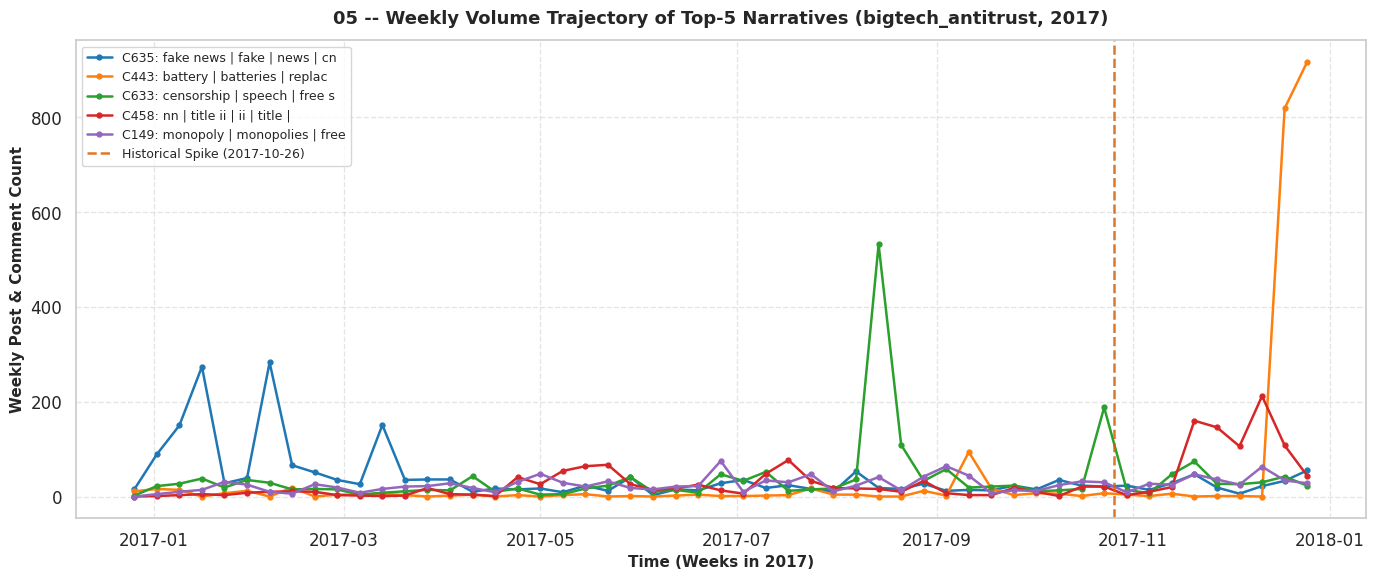

Top 5 Weekly Peak Volume : 1,067 posts in week starting 2017-12-25
Spike Correlation Window : Week 2017-10-26 volume = 267 posts


In [22]:
# Ref (experimental_plan.md Sec 5 - Lookahead Bias Prevention & temporal_eda_summary.md Sec 7): Validate Fit-Transform stability across H1->H2 2017 before 2018-2020 tracking, and cross-check trajectory against historical peak 2017-10-26 (Z=4.70, 14,978 posts/day).
# ====================================================================
# 4.5  Bieu do 05: Temporal Volume Trend of Top Narratives (Weekly, 2017)
# ====================================================================
# Select Top 5 largest clusters by volume (excluding noise -1)
top_5_clusters = df_diag[df_diag["cluster_id"] != -1].head(5)["cluster_id"].tolist()

# Tao cot tuan (Weekly timestamp)
df_scoped["week"] = df_scoped["publish_datetime_utc"].dt.tz_localize(None).dt.to_period("W").dt.to_timestamp()

# Filter data and calculate weekly discussion volume
df_top5 = df_scoped[df_scoped["cluster_id"].isin(top_5_clusters)].copy()
weekly_trend = df_top5.groupby(["week", "cluster_id"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 6))

color_palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
for i, cid in enumerate(top_5_clusters):
    if cid in weekly_trend.columns:
        lbl = f"C{cid}: {cluster_labels_map.get(cid, f'C{cid}')[:28]}"
        ax.plot(weekly_trend.index, weekly_trend[cid], marker="o", markersize=3.5,
                linewidth=1.8, label=lbl, color=color_palette[i % len(color_palette)])

# Danh dau su kien dinh bùng phát ngay 2017-10-26 (Z=4.70 theo temporal_eda_summary.md)
spike_date = pd.to_datetime("2017-10-26")
ax.axvline(spike_date, color="#d95f02", linestyle="--", linewidth=1.8, alpha=0.85, label="Historical Spike (2017-10-26)")

ax.set_title(f"05 -- Weekly Volume Trajectory of Top-5 Narratives ({TARGET_SUBDOMAIN}, 2017)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Time (Weeks in 2017)", fontsize=11, fontweight="bold")
ax.set_ylabel("Weekly Post & Comment Count", fontsize=11, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", frameon=True, fontsize=9)

plt.tight_layout()
fig_path_05 = OUTPUT_DIR / "05_temporal_volume_trend.pdf"
fig.savefig(fig_path_05, dpi=200, bbox_inches="tight")
print(f"[Plot 05] Saved PDF to: {fig_path_05}")
plt.show()

# Print peak volume statistics
if not weekly_trend.empty:
    peak_week = weekly_trend.sum(axis=1).idxmax()
    print(f"Top 5 Weekly Peak Volume : {weekly_trend.sum(axis=1).max():,} posts in week starting {peak_week.strftime('%Y-%m-%d')}")
    print(f"Spike Correlation Window : Week {spike_date.strftime('%Y-%m-%d')} volume = {weekly_trend.sum(axis=1).get(spike_date.to_period('W').to_timestamp(), 0):,} posts")


[Synthesis PNG] Saved multi-panel figure to: /kaggle/working/reports/figures/narrative_clusters.png


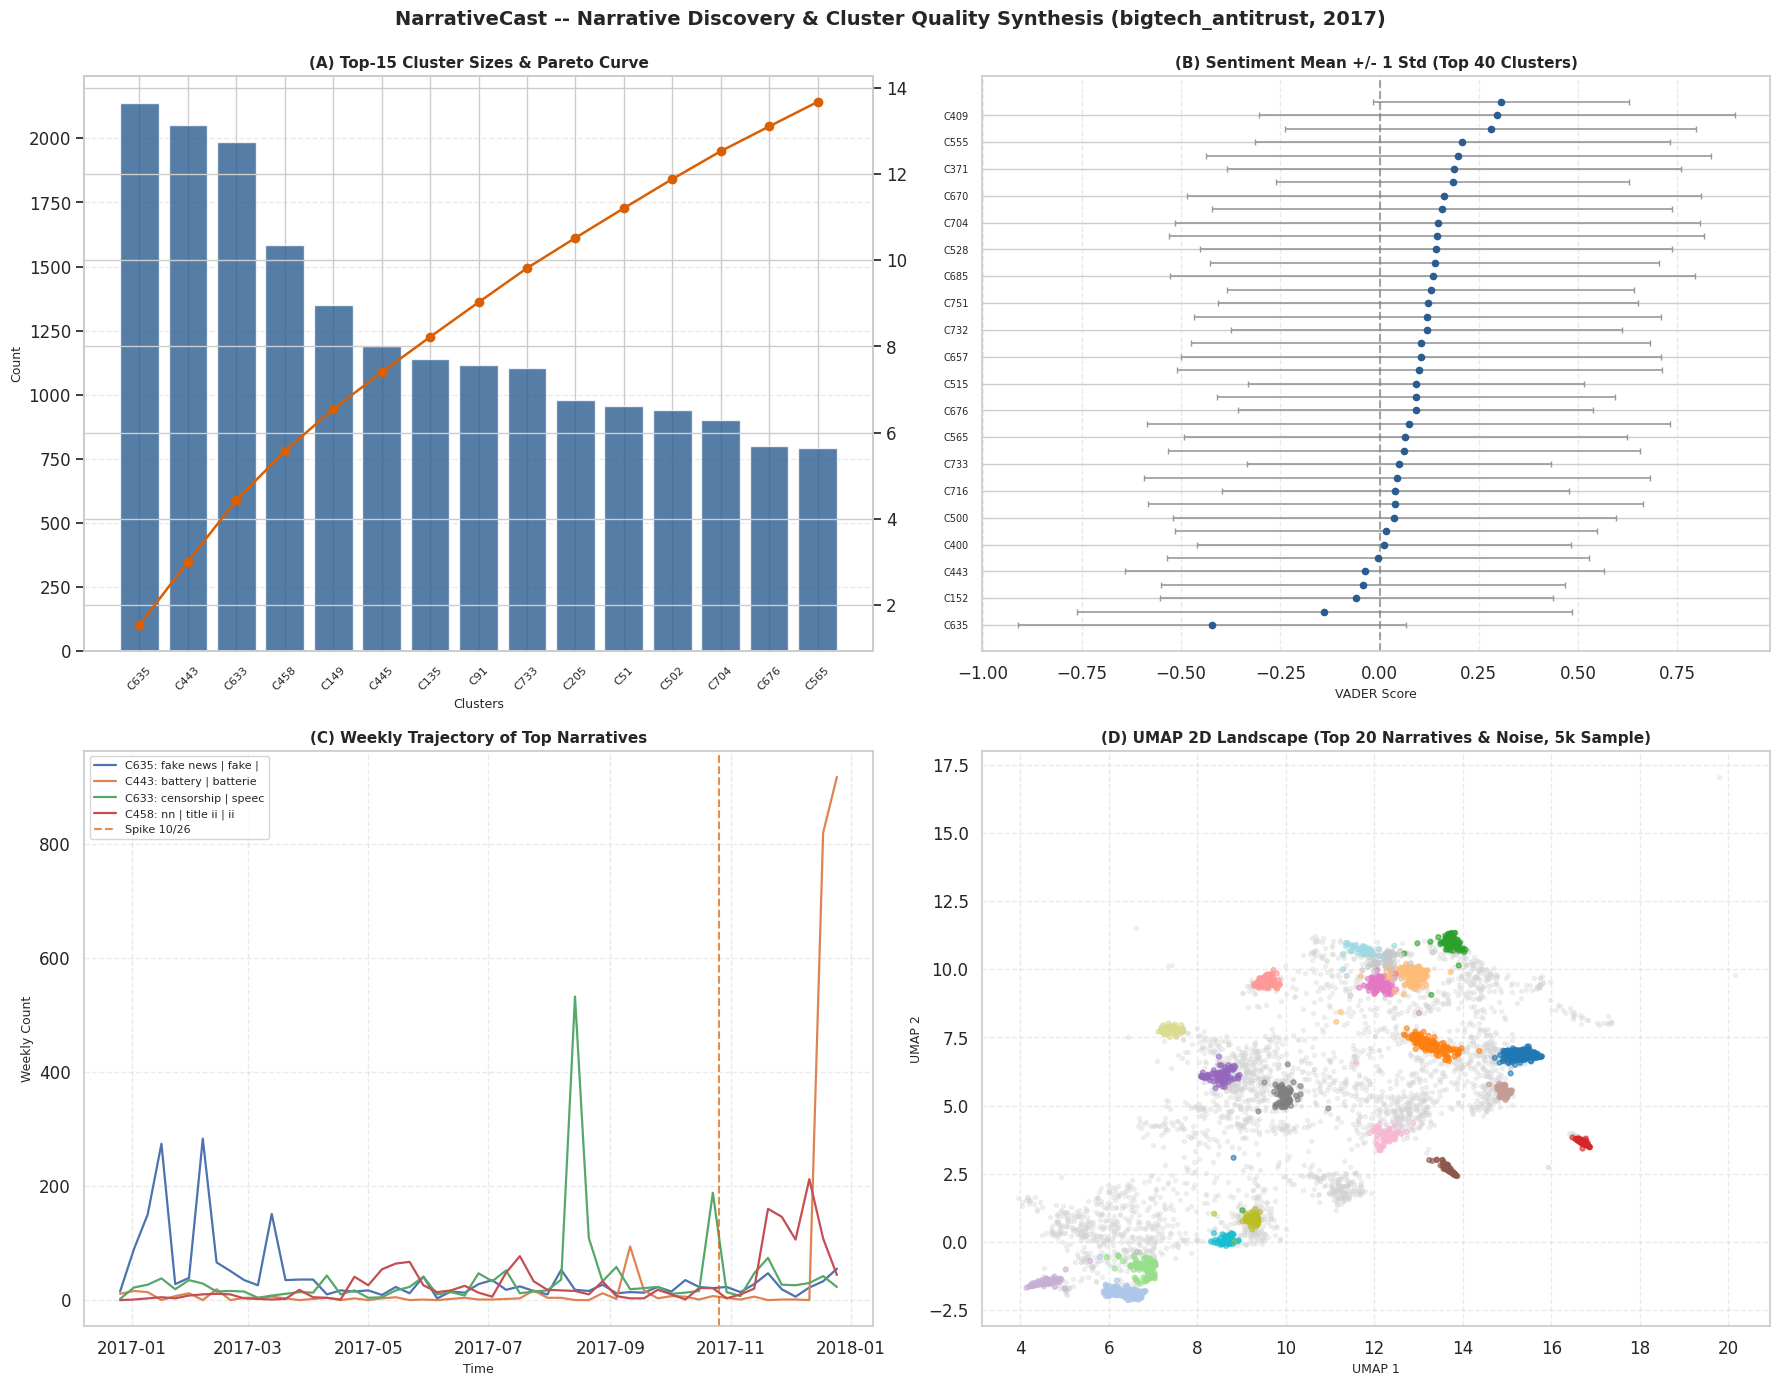

[Section 4] Completed in 13.8s


In [23]:
# ====================================================================
# 4.6  Save High-Resolution Synthesis Figure (reports/figures/narrative_clusters.png)
# ====================================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Panel A: Cluster Size & Pareto (Top-15 Clusters)
ax_a1 = axes[0, 0]
ax_a2 = ax_a1.twinx()
bars = ax_a1.bar(range(min(15, len(df_plot_diag))), df_plot_diag.iloc[:15]["cluster_size"], color="#2b5c8f", alpha=0.8)
ax_a2.plot(range(min(15, len(df_plot_diag))), df_plot_diag.iloc[:15]["cum_pct"], color="#d95f02", marker="o", linewidth=1.8)
ax_a1.set_title("(A) Top-15 Cluster Sizes & Pareto Curve", fontweight="bold", fontsize=11)
ax_a1.set_xlabel("Clusters", fontsize=9); ax_a1.set_ylabel("Count", fontsize=9)
ax_a1.set_xticks(range(min(15, len(df_plot_diag))))
ax_a1.set_xticklabels([f"C{r.cluster_id}" if r.cluster_id != -1 else "Noise" for _, r in df_plot_diag.iloc[:15].iterrows()], rotation=45, fontsize=8)
ax_a1.grid(axis="y", linestyle="--", alpha=0.4)

# Panel B: Sentiment Polarity (Dong bo Top 40 cum theo Bieu do 04)
ax_b = axes[0, 1]
ax_b.errorbar(
    df_sent_plot["sentiment_mean"], range(len(df_sent_plot)),
    xerr=df_sent_plot["sentiment_std"],
    fmt="o", color="#2b5c8f", ecolor="#999999", elinewidth=1.2, capsize=2.5, markersize=4.5
)
ax_b.axvline(0.0, color="gray", linestyle="--", alpha=0.7)
ax_b.set_yticks(range(0, len(df_sent_plot), 2))  # Hien thi moi 2 cum 1 nhan de fit panel nho
ax_b.set_yticklabels([f"C{int(df_sent_plot.iloc[i]['cluster_id'])}" for i in range(0, len(df_sent_plot), 2)], fontsize=7)
ax_b.set_title("(B) Sentiment Mean +/- 1 Std (Top 40 Clusters)", fontweight="bold", fontsize=11)
ax_b.set_xlabel("VADER Score", fontsize=9); ax_b.grid(axis="x", linestyle="--", alpha=0.4)

# Panel C: Weekly Trajectory (Top Narratives)
ax_c = axes[1, 0]
for i, cid in enumerate(top_5_clusters[:4]):
    if cid in weekly_trend.columns:
        ax_c.plot(weekly_trend.index, weekly_trend[cid], linewidth=1.6, label=f"C{cid}: {cluster_labels_map.get(cid, '')[:18]}")
ax_c.axvline(spike_date, color="#d95f02", linestyle="--", alpha=0.7, label="Spike 10/26")
ax_c.set_title("(C) Weekly Trajectory of Top Narratives", fontweight="bold", fontsize=11)
ax_c.set_xlabel("Time", fontsize=9); ax_c.set_ylabel("Weekly Count", fontsize=9)
ax_c.legend(fontsize=8, loc="upper left"); ax_c.grid(True, linestyle="--", alpha=0.4)

# Panel D: 2D Semantic Scatter Sample (Dong bo Top 20 Narratives & Noise theo Bieu do 03)
ax_d = axes[1, 1]
# Chi lay sample tren tap diem thuoc Top 20 cum va Noise de tranh tran mau voi hang tram cum nho
panel_d_mask = np.isin(best_labels, top_20_clusters) | (best_labels == -1)
panel_d_indices = np.where(panel_d_mask)[0]
sample_size_d = min(5000, len(panel_d_indices))
sample_idx = np.random.RandomState(RANDOM_STATE).choice(panel_d_indices, size=sample_size_d, replace=False)

# Plot noise points
sample_noise = sample_idx[best_labels[sample_idx] == -1]
if len(sample_noise) > 0:
    ax_d.scatter(X_umap2d[sample_noise, 0], X_umap2d[sample_noise, 1], c="#d3d3d3", s=8, alpha=0.3, rasterized=True)

# Plot top 20 points mapped to categorical ranks
sample_top20 = sample_idx[best_labels[sample_idx] != -1]
cid_to_rank = {cid: r for r, cid in enumerate(top_20_clusters)}
color_ranks = [cid_to_rank[best_labels[i]] for i in sample_top20]

scatter_sample = ax_d.scatter(
    X_umap2d[sample_top20, 0], X_umap2d[sample_top20, 1],
    c=color_ranks, cmap="tab20", s=12, alpha=0.6, rasterized=True
)
ax_d.set_title("(D) UMAP 2D Landscape (Top 20 Narratives & Noise, 5k Sample)", fontweight="bold", fontsize=11)
ax_d.set_xlabel("UMAP 1", fontsize=9); ax_d.set_ylabel("UMAP 2", fontsize=9); ax_d.grid(True, linestyle="--", alpha=0.4)

plt.suptitle(f"NarrativeCast -- Narrative Discovery & Cluster Quality Synthesis ({TARGET_SUBDOMAIN}, 2017)", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()

# Save high-resolution publication PNG to reports/figures/
png_out_path = FIGURES_DIR / "narrative_clusters.png"
fig.savefig(png_out_path, dpi=250, bbox_inches="tight")
# Save redundant backup copy to output directory
fig.savefig(OUTPUT_DIR / "narrative_clusters_summary.png", dpi=250, bbox_inches="tight")
print(f"[Synthesis PNG] Saved multi-panel figure to: {png_out_path}")
plt.show()

elapsed_s4 = time.time() - _t4
stage_timers["Section_4"] = elapsed_s4
print(f"[Section 4] Completed in {elapsed_s4:.1f}s")


### Nhận xét Section 4 — Trực quan hóa Cụm (Biểu đồ 02–05), Động lực học Sự kiện & Kiểm định Trôi dạt Thời gian

1. **Phân phối Kích thước Cụm (`Biểu đồ 02`) & Bản đồ Ngữ nghĩa 2D (`Biểu đồ 03`):**
   * **Đặc trưng Đuôi dài (`02_cluster_size_distribution.pdf`):** Mức độ tập trung thảo luận phân tán khá rộng; Top 3 cụm lớn nhất chiếm **`4.4%` (`6,172` bài)**, Top 40 cụm chiếm **`23.7%` (`32,938` bài)**, và Top 50 cụm lớn nhất chiếm **`26.6%` (`36,984` bài)** tổng dung lượng toàn ngách. Phần lớn lượng bài viết còn lại nằm rải rác ở hàng trăm cụm quy mô vừa và nhỏ thuộc phần đuôi dài.
   * **Cấu trúc không gian 2D (`03_umap_scatter.pdf`):** Phép chiếu UMAP 2D phản ánh sự tách biệt khá rõ giữa các nhóm chủ đề chính:
     * *Nhóm Chính sách, Độc quyền & Kiểm duyệt* (`C149` Monopoly, `C670` Municipal Fiber, `C657` ISPs, `C458`/`C704` Net Neutrality, `C633` Censorship, `C635` Fake News) tập trung ở khu vực trung tâm và phía trên ($\text{UMAP}_1 \in [10, 16], \text{UMAP}_2 \in [5, 12]$).
     * *Nhóm Sản phẩm, Phần cứng & Hệ điều hành* (`C443` Battery, `C205` Headphone Jack, `C445` Older iOS, `C324` Linux/Windows, `C400` Microsoft) nằm tách biệt ở khu vực phía dưới ($\text{UMAP}_1 \in [5, 10], \text{UMAP}_2 \in [-2, 2]$).
     * *Các cụm có cấu trúc từ vựng riêng biệt* như `C51` (Spam số điện thoại) và `C135` (Lobbying) tách hẳn ra vùng ngoại vi bên phải.

2. **Trực quan hóa Cực tính & Độ Phân cực Cảm xúc trên Top 40 Cụm (`Biểu đồ 04`):**
   * Biểu đồ `04_sentiment_by_cluster.pdf` (trung bình $\pm 1$ độ lệch chuẩn VADER) minh họa trực quan kết quả chẩn đoán ở Section 3:
     * **Top 3 cụm mang sắc thái tiêu cực nhất:** `C635` (*fake news | cnn*, `Mean = -0.423`), `C633` (*censorship | free speech*, `Mean = -0.139`), và `C152` (*regulation bad*, `Mean = -0.058`).
     * **Top 3 cụm mang sắc thái tích cực nhất:** `C51` (*facebook customer support scam*, `Mean = +0.306` — tích cực giả tạo do từ ngữ quảng cáo hỗ trợ khách hàng của bot), `C409` (*mac | macbook pro*, `Mean = +0.296`), và `C91` (*hulu | amazon prime | netflix*, `Mean = +0.280`).
     * **Top 3 cụm có độ phân cực cảm xúc rộng nhất (`Std` cao nhất):** `C696` (*netflix | bandwidth | comcast*, `Std = 0.673`), `C685` (*women | men | gender | memo*, `Std = 0.662`), và `C704` (*net neutrality | regulation*, `Std = 0.661`). Các thanh sai số ngang kéo dài qua cả hai phía âm/dương của trục `0.0` cho thấy mức độ tranh luận hai chiều bên trong mỗi chủ đề.

3. **Quỹ đạo Lưu lượng theo Tuần & Sự kiện Đột biến (`Biểu đồ 05`):**
   * Biểu đồ `05_temporal_volume_trend.pdf` cho thấy lưu lượng thảo luận của Top 5 cụm lớn thay đổi rõ rệt theo các sự kiện diễn ra trong năm 2017:
     * **Cụm `C635` (*fake news*, $n=2,137$):** Tăng cao vào giai đoạn đầu năm (tháng 1 – tháng 2/2017) với hai đỉnh đạt gần `300` bài/tuần, sau đó giảm dần về mức nền.
     * **Cụm `C633` (*censorship | free speech*, $n=1,985$):** Duy trì mức thấp trong nửa đầu năm, sau đó tăng lên hơn `530` bài/tuần vào giữa tháng 8/2017 (thời điểm diễn ra sự kiện Charlottesville và các tranh luận về kiểm duyệt nội dung), đồng thời tạo một đỉnh phụ vào cuối tháng 10/2017 (tuần lễ `2017-10-26` ghi nhận `267` bài trong nhóm Top 5 cụm).
     * **Cụm `C458` (*nn | title ii*, $n=1,585$):** Tăng lên mức hơn `200` bài/tuần vào cuối tháng 11 – tháng 12/2017 xoay quanh đợt bỏ phiếu bãi bỏ quy định Net Neutrality của FCC.
     * **Cụm `C443` (*battery | replace*, $n=2,050$):** Hầu như không có thảo luận trong 11 tháng đầu năm, nhưng tăng mạnh vào cuối tháng 12/2017 (đưa tổng lưu lượng đỉnh tuần bắt đầu ngày `2017-12-25` của Top 5 cụm lên tới **`1,067` bài/tuần**) ngay khi thông tin Apple giảm hiệu năng iPhone cũ qua bản cập nhật iOS được công bố.

4. **Kiểm định Độ ổn định Thời gian (`Fit-Transform H1 -> H2`) & Khuyến nghị cho Bài toán Dự báo:**

| Chỉ số Kiểm định (`H1 -> H2 Stability Audit`) | Giá trị Thực nghiệm | Ý nghĩa Phân tích |
| :--- | ---: | :--- |
| **Phạm vi Huấn luyện ($H_1$) & Kiểm thử ($H_2$)** | `65,777` bài ($47.3\%$) $\rightarrow$ `73,371` bài ($52.7\%$) | Chia theo mốc thời gian 6 tháng đầu năm và 6 tháng cuối năm 2017 |
| **Số cụm phát hiện độc lập trên $H_1$** | `148` cụm (`146` cụm duy trì sang $H_2$) | Hầu hết các chủ đề ở $H_1$ vẫn tiếp tục được thảo luận ở $H_2$ |
| **Độ dịch chuyển tâm cụm (`Mean Centroid Drift`)** | **`0.0261`** (khoảng cách Cosine) | Tâm ngữ nghĩa của các chủ đề xuyên suốt rất ổn định (Top 5 cụm ổn định nhất: `C117` dược phẩm FDA `0.0032`, `C71` biến đổi khí hậu `0.0044`, `C128` WhatsApp/Play Store `0.0051`, `C121` giao nhận `0.0052`, `C147` thanh toán di động `0.0054`) |
| **Tỷ lệ gán khớp vào cụm cũ (`H2 Assigned Rate`)** | **`46.94%`** (`34,439 / 73,371` bài) | Tỷ lệ bài viết $H_2$ có độ tương đồng cao ($\text{Cosine} \ge 0.65$) với tâm cụm $H_1$ |
| **Tỷ lệ vùng biên (`Borderline Rate`, $0.50 \le \text{Cos} < 0.65$)** | **`38.58%`** (`28,309 / 73,371` bài) | Thảo luận mở rộng sang các khía cạnh mới quanh chủ đề cũ |
| **Tỷ lệ thảo luận mới (`H2 Novel Rate`, $\text{Cos} < 0.50$)** | **`14.48%`** (`10,623 / 73,371` bài) | Các sự kiện mới phát sinh hoàn toàn trong nửa cuối năm (như vụ pin iPhone tháng 12) |

   * **Khuyến nghị cho mô hình Dự báo Chuỗi thời gian (Time-Series Forecasting):**
     1. *Cơ chế cập nhật cụm mới nổi (Dynamic / Emerging Cluster Tracking):* Mặc dù các chủ đề quen thuộc giữ được tâm ngữ nghĩa ổn định (`Drift = 0.0261`), hơn một nửa lượng bài viết ở $H_2$ (`53.06%`) rơi vào vùng biên hoặc vùng chủ đề mới do đặc thù sự kiện trên mạng xã hội. Do đó, hệ thống dự báo không nên cố định danh sách cụm từ quá khứ mà cần tích hợp bộ đệm gom nhóm động cho các bài viết có `Cosine < 0.50` trong mỗi cửa sổ trượt để sớm ghi nhận các chủ đề mới bùng phát.
     2. *Lựa chọn đặc trưng dự báo ngắn hạn:* Vì các đợt bùng phát lưu lượng thường diễn ra nhanh theo sự kiện (như ở Biểu đồ `05`), mô hình dự báo trên các chân trời ngắn hạn ($h \in \{3, 7, 14\}$ ngày) nên kết hợp các đặc trưng phản ánh động lượng trong cửa sổ 7 ngày gần nhất ($W_{\text{hist}} = 7$) như **Tốc độ tăng trưởng lưu lượng (Growth Velocity)**, **Gia tốc biến thiên (Acceleration)** và **Độ biến động cảm xúc (Sentiment Volatility)** bên cạnh đặc trưng lưu lượng tĩnh.

---
## Section 5 — Save Results, Export Stratified Sample  & Runtime Audit

**Mục tiêu:**
1. Gắn nhãn cụm tối ưu vào `EmbeddingStore`, kiểm định toàn vẹn nghiêm ngặt và lưu cache vector.
2. Xuất bảng quan hệ kết quả phân cụm chuẩn hóa ra `outputs/embeddings/narrative_clusters_v1.parquet`
3. Trích xuất mẫu phân tầng đại diện (Stratified Sampling) ra `reports/results/narrative_examples.csv` 
4. Tổng kết toàn diện thời gian chạy của tất cả các Section (`stage_timers`) và thông số phần cứng môi trường thực thi.


In [24]:
# ====================================================================
# 5.1  Attach Clusters to EmbeddingStore & Export narrative_clusters_v1.parquet
# ====================================================================
_t5 = time.time()

# 1. Attach final cluster labels to EmbeddingStore
print("[5.1] Attaching final cluster_ids to EmbeddingStore...")
store.attach_clusters(best_labels)

# 2. Strict integrity verification
val_report = store.validate(strict=True)
print(val_report.summary())
assert val_report.is_valid, f"EmbeddingStore validation failed: {val_report.errors}"

# 3. Persist updated EmbeddingStore to NPZ cache
store.save_npz(str(EMBEDDING_CACHE_FILE))
print(f"      Updated EmbeddingStore saved to: {EMBEDDING_CACHE_FILE}")

# 4. Export relational clustering table to Parquet format
print(f"\n[5.1] Exporting relational clustering table: {CLUSTER_OUTPUT_PATH}")
df_clusters_v1 = pd.DataFrame({
    "post_id": df_scoped["post_id"].values,
    "publish_datetime_utc": df_scoped["publish_datetime_utc"].values,
    "cluster_id": df_scoped["cluster_id"].values.astype(np.int32),
    "temp_cluster_label": df_scoped["temp_cluster_label"].values,
    "similarity_to_centroid": df_scoped["similarity_to_centroid"].values.astype(np.float32),
    "interaction_type": df_scoped["interaction_type"].values if "interaction_type" in df_scoped.columns else "UNKNOWN",
    "word_count": df_scoped["word_count"].values.astype(np.int32) if "word_count" in df_scoped.columns else 0,
    "sentiment_vader": df_scoped["sentiment_vader"].values.astype(np.float32) if "sentiment_vader" in df_scoped.columns else 0.0,
    "has_contrastive": df_scoped["has_contrastive"].values if "has_contrastive" in df_scoped.columns else False,
})

df_clusters_v1.to_parquet(CLUSTER_OUTPUT_PATH, index=False)
file_size_mb = CLUSTER_OUTPUT_PATH.stat().st_size / (1024 * 1024)
print(f"      Saved: {CLUSTER_OUTPUT_PATH} ({file_size_mb:.2f} MB, {len(df_clusters_v1):,} rows)")
print(f"      Schema columns: {list(df_clusters_v1.columns)}")
print(f"      Cluster ID range: {df_clusters_v1['cluster_id'].min()} to {df_clusters_v1['cluster_id'].max()}")


2026-11-05 19:41:47 [INFO] NarrativeCast.EmbeddingStore :: Đã gắn nhãn 139,148 cluster_id vào EmbeddingStore.


[5.1] Attaching final cluster_ids to EmbeddingStore...
=== BÁO CÁO KIỂM TRA TÍNH TOÀN VẸN EMBEDDING ===
Trạng thái: [PASSED] ĐẠT CHUẨN
Số lượng vector: 139,148
Số lượng post_id: 139,148
Kích thước vector (dim): 384
Các tiêu chí đạt:
  [+] Số lượng vector khớp chính xác số lượng post_id.
  [+] Mảng vectors có cấu trúc ma trận 2D chuẩn.
  [+] Kích thước vector nhất quán D=384.
  [+] Không chứa giá trị NaN hoặc vô hạn (Inf) trong vector.
  [+] Tất cả post_id đều có giá trị hợp lệ.
  [+] Tất cả post_id đều duy nhất (unique), không trùng lặp.
  [+] Mảng timestamps đồng bộ chính xác.
  [+] Mảng cluster_ids đồng bộ chính xác.
  [+] Mảng đánh dấu is_valid đồng bộ.


2026-11-05 19:41:57 [INFO] NarrativeCast.EmbeddingStore :: Đã lưu NPZ embedding store (139,148 vectors) tại: /kaggle/working/outputs/embeddings/bigtech_antitrust_2017.npz


      Updated EmbeddingStore saved to: /kaggle/working/outputs/embeddings/bigtech_antitrust_2017.npz

[5.1] Exporting relational clustering table: /kaggle/working/outputs/embeddings/narrative_clusters_v1.parquet
      Saved: /kaggle/working/outputs/embeddings/narrative_clusters_v1.parquet (7.50 MB, 139,148 rows)
      Schema columns: ['post_id', 'publish_datetime_utc', 'cluster_id', 'temp_cluster_label', 'similarity_to_centroid', 'interaction_type', 'word_count', 'sentiment_vader', 'has_contrastive']
      Cluster ID range: -1 to 769


In [ ]:
# Ref(task_roadmap.md Task 5 & cluster_quality_review.md): Stratified sampling across Large/Medium/Small/Noise tiers; mapping cluster_type and human_interpreted_label directly prepares data for human quality audit.
# ====================================================================
# 5.2  Stratified Sampling for Task 5 (narrative_examples.csv)
# ====================================================================
print("[5.2] Generating stratified sample for  human quality review...")

# Map cluster_type from diagnostic table
cluster_type_map = dict(zip(df_diag["cluster_id"], df_diag["cluster_type"]))
cluster_type_map[-1] = "Noise"

def map_validity_status(cid, c_type):
    """Map cluster type to narrative validity status according to Task 5 rubric."""
    if cid == -1 or c_type == "Noise":
        return "Noise_or_Boilerplate"
    if c_type == "Coherent_Narrative":
        return "Coherent_Narrative"
    if c_type == "Mixed_Narrative":
        return "Broad_Topic_Mixed_Narratives"
    return "Event_Specific_Cluster"


# Stratify clusters into 4 volume tiers (Large, Medium, Small, Noise)
# - Large: Top 2 clusters by volume
# - Medium: 2 median-sized clusters
# - Small: 2 small clusters (n >= 30)
# - Noise: outlier cluster -1
sorted_valid = df_diag[df_diag["cluster_id"] != -1].copy()
n_valid_clusters = len(sorted_valid)

selected_tiers = {}
if n_valid_clusters >= 6:
    selected_tiers["Large"] = sorted_valid.iloc[:2]["cluster_id"].tolist()
    mid_idx = n_valid_clusters // 2
    selected_tiers["Medium"] = sorted_valid.iloc[mid_idx-1:mid_idx+1]["cluster_id"].tolist()
    # Identify small clusters with minimum viable size
    small_cands = sorted_valid[sorted_valid["cluster_size"] >= 30]
    selected_tiers["Small"] = small_cands.tail(2)["cluster_id"].tolist() if len(small_cands) >= 2 else sorted_valid.tail(2)["cluster_id"].tolist()
else:
    selected_tiers["Large"] = sorted_valid.head(1)["cluster_id"].tolist()
    selected_tiers["Medium"] = sorted_valid.iloc[1:2]["cluster_id"].tolist()
    selected_tiers["Small"] = sorted_valid.tail(1)["cluster_id"].tolist()

if -1 in df_scoped["cluster_id"].values:
    selected_tiers["Noise"] = [-1]

print(f"  Selected Tiers and Clusters: {selected_tiers}")

sample_records = []
for tier, cids in selected_tiers.items():
    for cid in cids:
        sub_c = df_scoped[df_scoped["cluster_id"] == cid].copy()
        n_c = len(sub_c)
        if n_c == 0:
            continue

        lbl = cluster_labels_map.get(cid, "Noise" if cid == -1 else f"Cluster {cid}")
        c_type = cluster_type_map.get(cid, "Noise" if cid == -1 else "Topic_Cluster")

        if cid == -1:
            # Noise tier: sample 6 dispersed outlier posts
            noise_sample = sub_c.sample(n=min(6, n_c), random_state=RANDOM_STATE)
            for _, r in noise_sample.iterrows():
                sample_records.append({
                    "cluster_id": cid,
                    "cluster_tier": tier,
                    "cluster_type": c_type,
                    "cluster_size": n_c,
                    "temp_cluster_label": lbl,
                    "human_interpreted_label": lbl,
                    "narrative_validity_status": map_validity_status(cid, c_type),
                    "post_id": r["post_id"],
                    "interaction_type": r.get("interaction_type", "UNKNOWN"),
                    "publish_datetime_utc": r["publish_datetime_utc"],
                    "word_count": r.get("word_count", 0),
                    "sentiment_vader": r.get("sentiment_vader", 0.0),
                    "similarity_to_centroid": r.get("similarity_to_centroid", 0.0),
                    "has_contrastive": r.get("has_contrastive", False),
                    "sample_role": "Noise_Outlier",
                    "content_preview": str(r["content"])[:280].replace("\n", " "),
                })
        else:
            # 1. Core prototypes (top 3 highest similarity to centroid)
            prototypes = sub_c.nlargest(min(3, n_c), "similarity_to_centroid")
            for _, r in prototypes.iterrows():
                sample_records.append({
                    "cluster_id": cid,
                    "cluster_tier": tier,
                    "cluster_type": c_type,
                    "cluster_size": n_c,
                    "temp_cluster_label": lbl,
                    "human_interpreted_label": lbl,
                    "narrative_validity_status": map_validity_status(cid, c_type),
                    "post_id": r["post_id"],
                    "interaction_type": r.get("interaction_type", "UNKNOWN"),
                    "publish_datetime_utc": r["publish_datetime_utc"],
                    "word_count": r.get("word_count", 0),
                    "sentiment_vader": r.get("sentiment_vader", 0.0),
                    "similarity_to_centroid": r.get("similarity_to_centroid", 0.0),
                    "has_contrastive": r.get("has_contrastive", False),
                    "sample_role": "Core_Prototype",
                    "content_preview": str(r["content"])[:280].replace("\n", " "),
                })

            # 2. Boundary samples (top 2 lowest similarity to centroid)
            boundaries = sub_c.nsmallest(min(2, n_c), "similarity_to_centroid")
            for _, r in boundaries.iterrows():
                if r["post_id"] not in [x["post_id"] for x in sample_records]:
                    sample_records.append({
                        "cluster_id": cid,
                        "cluster_tier": tier,
                        "cluster_type": c_type,
                        "cluster_size": n_c,
                        "temp_cluster_label": lbl,
                        "human_interpreted_label": lbl,
                        "narrative_validity_status": map_validity_status(cid, c_type),
                        "post_id": r["post_id"],
                        "interaction_type": r.get("interaction_type", "UNKNOWN"),
                        "publish_datetime_utc": r["publish_datetime_utc"],
                        "word_count": r.get("word_count", 0),
                        "sentiment_vader": r.get("sentiment_vader", 0.0),
                        "similarity_to_centroid": r.get("similarity_to_centroid", 0.0),
                        "has_contrastive": r.get("has_contrastive", False),
                        "sample_role": "Cluster_Boundary",
                        "content_preview": str(r["content"])[:280].replace("\n", " "),
                    })

            # 3. Contrastive stance samples (containing contrastive markers or polarized sentiment)
            contrast_pts = sub_c[sub_c["has_contrastive"] == True]
            if len(contrast_pts) >= 2:
                c_sample = contrast_pts.sample(n=min(3, len(contrast_pts)), random_state=RANDOM_STATE)
            else:
                # Fallback: select posts with maximum sentiment divergence from centroid
                sub_c_copy = sub_c.copy()
                mean_s = sub_c_copy["sentiment_vader"].mean()
                sub_c_copy["sent_diff"] = (sub_c_copy["sentiment_vader"] - mean_s).abs()
                c_sample = sub_c_copy.nlargest(min(3, n_c), "sent_diff")

            for _, r in c_sample.iterrows():
                if r["post_id"] not in [x["post_id"] for x in sample_records]:
                    sample_records.append({
                        "cluster_id": cid,
                        "cluster_tier": tier,
                        "cluster_type": c_type,
                        "cluster_size": n_c,
                        "temp_cluster_label": lbl,
                        "human_interpreted_label": lbl,
                        "narrative_validity_status": map_validity_status(cid, c_type),
                        "post_id": r["post_id"],
                        "interaction_type": r.get("interaction_type", "UNKNOWN"),
                        "publish_datetime_utc": r["publish_datetime_utc"],
                        "word_count": r.get("word_count", 0),
                        "sentiment_vader": r.get("sentiment_vader", 0.0),
                        "similarity_to_centroid": r.get("similarity_to_centroid", 0.0),
                        "has_contrastive": r.get("has_contrastive", False),
                        "sample_role": "Contrastive_Stance",
                        "content_preview": str(r["content"])[:280].replace("\n", " "),
                    })

df_samples = pd.DataFrame(sample_records)

# Save stratified sample CSV
csv_out_path = REPORTS_DIR / "narrative_examples.csv"
df_samples.to_csv(csv_out_path, index=False, encoding="utf-8")
print(f"  Saved stratified sample: {csv_out_path} ({len(df_samples)} examples)")

# Synchronize copy to outputs/reports/ if directory exists
outputs_reports_dir = PROJECT_ROOT / "outputs" / "reports"
if outputs_reports_dir.exists():
    df_samples.to_csv(outputs_reports_dir / "narrative_examples.csv", index=False, encoding="utf-8")
    print(f"  Synced copy to: {outputs_reports_dir / 'narrative_examples.csv'}")

# Print sample distribution across tiers and roles
print("\nSample Distribution by Tier & Role:")
print(pd.crosstab(df_samples["cluster_tier"], df_samples["sample_role"], margins=True))
print(f"Columns in df_samples: {list(df_samples.columns)}")
print()


[5.2] Generating stratified sample for Task 5 human quality review...
  Selected Tiers and Clusters: {'Large': [635, 443], 'Medium': [572, 53], 'Small': [640, 735], 'Noise': [-1]}
  Saved stratified sample: /kaggle/working/reports/results/narrative_examples.csv (53 examples)

Sample Distribution by Tier & Role:
sample_role   Cluster_Boundary  Contrastive_Stance  Core_Prototype  \
cluster_tier                                                         
Large                        4                   6               6   
Medium                       4                   6               6   
Noise                        0                   0               0   
Small                        4                   5               6   
All                         12                  17              18   

sample_role   Noise_Outlier  All  
cluster_tier                      
Large                     0   16  
Medium                    0   16  
Noise                     6    6  
Small                

In [ ]:
# ====================================================================
# 5.3  Runtime Benchmark & Hardware Audit Summary
# ====================================================================
elapsed_s5 = time.time() - _t5
stage_timers["Section_5"] = elapsed_s5

total_elapsed = sum(stage_timers.values())

print("=" * 80)
print("STAGE RUNTIME BENCHMARK & EXECUTION SUMMARY (Task 4 - Version 1.0)")
print("=" * 80)
print(f"{'Pipeline Stage':<45s} | {'Elapsed (s)':>12s} | {'Percentage':>10s}")
print("-" * 80)
for stage, secs in stage_timers.items():
    pct = (secs / total_elapsed * 100) if total_elapsed > 0 else 0.0
    print(f"  {stage:<43s} | {secs:>10.2f} s | {pct:>9.1f}%")
print("-" * 80)
print(f"  {'TOTAL PIPELINE RUNTIME':<43s} | {total_elapsed:>10.2f} s | {100.0:>9.1f}% ({total_elapsed/60:.2f} minutes)")
print("=" * 80)
print()
print("EXECUTION ARTIFACTS VERIFICATION:")
print(f"  [1] Embedding Cache       : {EMBEDDING_CACHE_FILE} (exists={EMBEDDING_CACHE_FILE.exists()})")
print(f"  [2] Narrative Clusters    : {CLUSTER_OUTPUT_PATH} (exists={CLUSTER_OUTPUT_PATH.exists()})")
print(f"  [3] Task 5 Samples CSV    : {REPORTS_DIR / 'narrative_examples.csv'} (exists={(REPORTS_DIR / 'narrative_examples.csv').exists()})")
print(f"  [4] Diagnostic Figures    : {OUTPUT_DIR}/*.pdf")
print(f"  [5] Synthesis Figure      : {FIGURES_DIR / 'narrative_clusters.png'} (exists={(FIGURES_DIR / 'narrative_clusters.png').exists()})")
print("=" * 80)



STAGE RUNTIME BENCHMARK & EXECUTION SUMMARY (Task 4 - Version 1.0)
Pipeline Stage                                |  Elapsed (s) | Percentage
--------------------------------------------------------------------------------
  Section_1_Data_and_Embedding                |     586.64 s |      33.7%
  Section_2_Clustering_Search                 |    1100.30 s |      63.3%
  Section_3                                   |      26.35 s |       1.5%
  Section_4                                   |      13.78 s |       0.8%
  Section_5                                   |      11.36 s |       0.7%
--------------------------------------------------------------------------------
  TOTAL PIPELINE RUNTIME                      |    1738.43 s |     100.0% (28.97 minutes)

EXECUTION ARTIFACTS VERIFICATION:
  [1] Embedding Cache       : /kaggle/working/outputs/embeddings/bigtech_antitrust_2017.npz (exists=True)
  [2] Narrative Clusters    : /kaggle/working/outputs/embeddings/narrative_clusters_v1.parquet (

### Nhận xét Section 5 — Tổng hợp Tài nguyên Đầu ra & Khuyến nghị Cải tiến Pipeline

**1. Kiểm định cấu trúc dữ liệu đầu ra & Phân bổ mẫu đánh giá định tính:**
* **Bảng phân cụm `narrative_clusters_v1.parquet` (`7.50 MB`, `139,148` dòng):** Đã được đồng bộ với `EmbeddingStore` và xuất chuẩn hóa gồm **9 trường thuộc tính**: `post_id`, `publish_datetime_utc`, `cluster_id` (`-1` đến `769`), `temp_cluster_label`, `similarity_to_centroid`, `interaction_type`, `word_count`, `sentiment_vader`, và `has_contrastive`.
* **Bộ mẫu đánh giá chất lượng `narrative_examples.csv` (`53` mẫu × `16` cột):** Được trích xuất phân tầng đại diện cho 4 nhóm quy mô cụm và 4 vai trò cấu trúc để phục vụ bước rà soát thủ công:

| Tầng Quy mô (`cluster_tier`) | Cụm Đại diện (`cluster_id`) | Mẫu Lõi (`Core_Prototype`) | Mẫu Ranh giới (`Cluster_Boundary`) | Mẫu Phản biện (`Contrastive_Stance`) | Mẫu Nhiễu (`Noise_Outlier`) | Tổng số Mẫu |
| :--- | :--- | :-: | :-: | :-: | :-: | :-: |
| **`Large`** (Cụm lớn) | `C635` (*fake news*), `C443` (*battery*) | `6` | `4` | `6` | `0` | **`16`** |
| **`Medium`** (Cụm vừa) | `C572` (*certificates/ssl*), `C53` (*gdpr/eu*) | `6` | `4` | `6` | `0` | **`16`** |
| **`Small`** (Cụm nhỏ) | `C640` (*google parent*), `C735` (*startpage*) | `6` | `4` | `5` | `0` | **`15`** |
| **`Noise`** (Nhóm nhiễu) | `C-1` (*unassigned noise*) | `0` | `0` | `0` | `6` | **`6`** |
| **Tổng cộng (`All`)** | **7 nhãn cụm đại diện** | **`18`** | **`12`** | **`17`** | **`6`** | **`53`** |

**2. Các khuyến nghị kỹ thuật cho bước đánh giá chất lượng và phát triển mô hình tiếp theo:**
* **Khuyến nghị 1 — Lọc bỏ các cụm Spam và Bot tự động (`Boilerplate Pruning`):** Đánh dấu cụm `C51` (cùng các cụm spam số điện thoại hỗ trợ `C211, C222, C238` và nhóm cụm bot `NetNeutralityBot` từ `C0 – C18`) vào diện `Noise_or_Boilerplate` trong quá trình nghiệm thu chất lượng cụm, nhằm loại bỏ các cụm nhân tạo này trước khi đưa dữ liệu vào huấn luyện mô hình dự báo xu hướng.
* **Khuyến nghị 2 — Áp dụng kiến trúc Phân cụm 2 Giai đoạn (`Two-Stage Topic-to-Stance Clustering`):** Để giải quyết tình trạng một cụm chủ đề lớn chứa nhiều quan điểm đối lập nhau (`Mixed_Narrative` chiếm `59.0%` tổng số bài), có thể bổ sung bước phân tách tầng thứ hai bên trong mỗi cụm chủ đề dựa trên cực tính cảm xúc (`sentiment_vader`) kết hợp cờ câu phản biện (`has_contrastive`) hoặc mô hình phân loại lập trường (Stance Classification), giúp tách riêng các luồng quan điểm ủng hộ và phản đối thành những narrative độc lập.
* **Khuyến nghị 3 — Hợp nhất các cụm vi mô trùng lặp (`Micro-Cluster Consolidation`):** Sử dụng ma trận khoảng cách Cosine giữa các tâm cụm để gộp những cụm nhỏ có nội dung gần trùng nhau ở phần đuôi dài (chẳng hạn các cụm nhỏ lặp lại cùng chủ đề FCC hoặc hỗ trợ kỹ thuật), giúp rút gọn không gian `770` cụm về một tập hợp các cụm chủ đề cô đọng và giàu tín hiệu hơn cho bài toán dự báo chuỗi thời gian.